# GKD student HP exploration — `20260727_slbreadth_160m`

End-to-end analysis of the **Stage A student-HP breadth screen** on the completed
campaign run-set **`20260727_slbreadth_160m`**. Teachers come from
`sdf_teachers/20260726_crossinit_160m`. The student under test is
**`pythia-160m-data-seed1`** (same-init spine + the A1/A3 weight-seed1 cross arm).

All tables and figures are loaded **live** from disk under
`{output_root}/gkd_students/20260727_slbreadth_160m/`. This notebook is
**strictly read-only** on cached outputs — every cell only reads JSON/JSONL under
`output_root`; nothing here writes back into `gkd_students/`.

**Run from the repo root** with the project venv:
```bash
uv sync --group analysis
uv run jupyter lab
```
Open `notebooks/gkd_student_hp_exploration.ipynb` and run all cells top-to-bottom.
Probe trajectories take ~60s to load once in Setup; subsequent cells reuse that frame.

---

## What this campaign tests

Stage A screens the student LoRA / LR / epoch surface for on-policy GKD
subliminal learning (Cloud et al.), asking:

1. Where on the `(r, α, lr)` surface does probe `p_target` rise — and where does it collapse?
2. Is there a monotone **lr × α law**, or an inverted-U / ridge?
3. Does **β ∈ {0, 1}** matter on a paired grid? (Plan §3.1: unexplored in the literature.)
4. Does a longer **epoch dose** buy more SL, or is peak-then-decay the norm?
5. Does the **same-init vs cross-init arm** at matched HP look like a lineage sanity check (not a causal factorial verdict)?
6. Do eval-grade `subliminal_delta` and forced-choice / capability guardrails confirm the probe screen on the sparse covered configs?

---

## Metric definitions (grades of evidence)

| Metric | Grade | Definition |
|---|---|---|
| **probe `p_target`** | **screen-wide** (in-training) | Preference probe during GKD; primary HP-screen metric because most A1 cells have no post-hoc eval |
| **`subliminal_delta`** | **eval-grade** (confirmatory) | `p(target)_treatment − p(target)_matched-control` on a held-out preference set (`gkd_results_io.subliminal_delta`) |
| **`subliminal_delta_ci`** | **eval-grade + uncertainty** | Paired multi-seed t-CI of the same delta |
| **FC `target_share_mean`** | **specificity** | Softmax over a fixed animal candidate set, renormalized; share on the target |
| **`perplexity_ratio`** | **capability guardrail** | Student PPL / base PPL — **this tree has no `bench_*` columns** |
| **`diverged`** | **QC flag** | Leaf flagged when any probe metric is non-finite or later `ppl` > `DIVERGENCE_PPL_FACTOR`× first probe ppl (`= 10`) |

**Aggregation rule used throughout:** filter `~diverged` before any probe-metric
mean/heatmap/correlation. End-of-run = last probe step per leaf
(`campaign.selection.end_of_run_probes`). Peak = max `p_target` per leaf
(`peak_probes`).

---

## Scope — HP surface only (critical)

```python
HP_STUDENT = "pythia-160m-data-seed1"
# same-init: teacher_base_label is NaN (no _tbase- suffix)
# cross arm: teacher_base_label == "weight-seed1"
def hp_scope(df):
    return df[(df["model"] == HP_STUDENT)
              & (df["teacher_base_label"].isna()
                 | (df["teacher_base_label"] == "weight-seed1"))]
```

**In scope:** HP treatments + matched controls on `pythia-160m-data-seed1` with
same-init teachers or the weight-seed1 cross arm.

**Out of scope — Stage B cross-init factorial:** every other student base
(`pythia-160m`, `-data-seed2/3`, `-weight-seed2/3`, `-weight-seed1` as student).
**Do not analyse Stage B pairwise `subliminal_delta` here.**

> **E2 pre-registration boundary** (`docs/MECHANISTIC_SL_EXPERIMENT_PLAN.md` §4 E2):
> the Stage B pairwise `subliminal_delta` table must **not** be analysed before the
> E2 pre-registration is filed. That analysis is deferred to
> `gkd_cross_init_factorial.ipynb`. The **same-init vs cross arm at matched HP**
> (§12) is part of the HP-screen design and is only a **lineage sanity check**,
> not the factorial verdict.

---

## Glossary of tag tokens

| Token | Meaning |
|---|---|
| **`gkd_tag`** | `lmb{λ}_b{β}_lora_lr{lr}_e{epochs}_r{r}a{α}` — student axes |
| **`teacher_tag`** | `sdf-{param_tag}-tfs{n}[_tbase-{variant}]` — biased teacher lineage |
| **`_tbase-{variant}`** | Present ⇒ cross-init teacher base; absent ⇒ same-init |
| **`tfs` / `teacher_ftseed`** | Teacher fine-tune seed |
| **`gseed`** | Student init + data-order seed |
| **λ (`lmbda`)** | On-policy fraction (fixed `1.0` here) |
| **β (`beta`)** | Generalized-JSD mixture (`0` = forward KL, `1` = reverse KL) |
| **`test` / `validation` / …** | Preference prompt sets (six here; **no `storytelling`**) |

---

## Section map

| § | Topic |
|---|---|
| 0 | Campaign provenance |
| 1 | Inventory & coverage audit |
| 2 | Control floor (A2 gate) |
| 3 | HP surface money-plot heatmaps |
| 4 | lr × α law? (inverted-U) |
| 5 | Divergence / instability map |
| 6 | β = 0 vs β = 1 |
| 7 | Dose ladder & trajectories |
| 8 | Emergence timing (novel threshold) |
| 9 | Capability guardrail |
| 10 | Forced-choice specificity |
| 11 | Eval-grade confirmation + freeze reconciliation |
| 12 | Same-init vs cross arm (sanity, not E2) |
| 13 | Teacher-seed (`tfs`) noise |
| 14 | Takeaways checklist |


## Setup


In [1]:
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy.stats import spearmanr

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

OUTPUT_ROOT = Path(
    yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())["output_root"]
)
SUBDIR = "gkd_students/20260727_slbreadth_160m"
TREE = OUTPUT_ROOT / SUBDIR
assert TREE.exists(), f"expected run tree missing: {TREE}"

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import add_lora_label
from subliminal_learning.campaign.selection import end_of_run_probes, peak_probes
from subliminal_learning.evaluation.gkd_results_io import (
    DIVERGENCE_PPL_FACTOR,
    load_gkd_capability_results,
    load_gkd_forced_choice_results,
    load_gkd_preference_results,
    load_gkd_probe_trajectories,
    subliminal_delta,
    subliminal_delta_ci,
    subliminal_delta_sign_test,
)
from subliminal_learning.evaluation.preference_scoring import sign_test

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.max_open_warning": 50,
})

HP_STUDENT = "pythia-160m-data-seed1"
PROMPT_SETS = ["consensus", "dislike", "favorite", "register", "test", "validation"]
SET_ORDER = PROMPT_SETS


def hp_scope(df: pd.DataFrame) -> pd.DataFrame:
    # HP surface: data-seed1 student, same-init or weight-seed1 cross teachers.
    return df[
        (df["model"] == HP_STUDENT)
        & (
            df["teacher_base_label"].isna()
            | (df["teacher_base_label"] == "weight-seed1")
        )
    ].copy()


def with_lora_label(df: pd.DataFrame) -> pd.DataFrame:
    # Alias student LoRA cols then attach ordered lora_label.
    out = df.copy()
    out["lora_r"] = out["student_lora_r"]
    out["lora_alpha"] = out["student_lora_alpha"]
    return add_lora_label(out)


def healthy(df: pd.DataFrame) -> pd.DataFrame:
    # Drop diverged probe leaves (when the column exists).
    if "diverged" not in df.columns:
        return df.copy()
    return df[~df["diverged"]].copy()


def same_init(df: pd.DataFrame) -> pd.DataFrame:
    return df[df["teacher_base_label"].isna() & ~df["is_control"]].copy()


def cross_arm(df: pd.DataFrame) -> pd.DataFrame:
    return df[
        (df["teacher_base_label"] == "weight-seed1") & ~df["is_control"]
    ].copy()


def mean_ci(series: pd.Series, z: float = 1.96) -> tuple[float, float, float, int]:
    s = series.dropna().astype(float)
    n = len(s)
    if n == 0:
        return float("nan"), float("nan"), float("nan"), 0
    m = float(s.mean())
    if n == 1:
        return m, m, m, 1
    se = float(s.std(ddof=1)) / math.sqrt(n)
    return m, m - z * se, m + z * se, n


print("output_root:", OUTPUT_ROOT)
print("subdir     :", SUBDIR)
print("tree       :", TREE)
print("tree.is_symlink():", TREE.is_symlink(), "resolve:", TREE.resolve())
assert not str(TREE).startswith("/mnt/ssd-1"), (
    "use output_root path (SSD-2), never hardcode /mnt/ssd-1"
)
if TREE.is_symlink():
    print(
        "WARNING: tree is still a cold-archive symlink → SSD-1; "
        "expect slow loads until restore cutover completes."
    )
else:
    print("tree is a real SSD-2 directory (hot).")

print("Setup helpers OK.")


output_root: /mnt/ssd-2/soar-subliminal/vishesh/subliminal_learning
subdir     : gkd_students/20260727_slbreadth_160m
tree       : /mnt/ssd-2/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260727_slbreadth_160m
Setup helpers OK.


In [2]:
print("Loading probe trajectories (this can take ~60s)...")
probes_all = load_gkd_probe_trajectories(OUTPUT_ROOT, SUBDIR)
print(f"  probes_all: {len(probes_all)} rows, "
      f"{probes_all['run_dir'].nunique()} leaves")

print("Loading preference / FC / capability...")
pref_all = load_gkd_preference_results(OUTPUT_ROOT, SUBDIR)
fc_all = load_gkd_forced_choice_results(OUTPUT_ROOT, SUBDIR)
cap_all = load_gkd_capability_results(OUTPUT_ROOT, SUBDIR)
print(f"  pref_all: {len(pref_all)}  fc_all: {len(fc_all)}  cap_all: {len(cap_all)}")

probes = hp_scope(probes_all)
pref = hp_scope(pref_all)
fc = hp_scope(fc_all)
cap = hp_scope(cap_all)
assert not probes.empty, "HP-scope probes empty"
assert not pref.empty, "HP-scope preference empty"

probes_h = healthy(probes)
eor = end_of_run_probes(probes_h)
eor_treat = eor[~eor["is_control"]].copy()
eor_ctrl = eor[eor["is_control"]].copy()
peak = peak_probes(probes_h)
peak_treat = peak[~peak["is_control"]].copy()

print(
    f"HP scope — probe rows: {len(probes)} | healthy leaves: "
    f"{probes_h['run_dir'].nunique()} | end-of-run treat: {len(eor_treat)} | "
    f"end-of-run ctrl: {len(eor_ctrl)}"
)
print("Load complete.")


Loading probe trajectories (this can take ~60s)...
  probes_all: 30348 rows, 1073 leaves
Loading preference / FC / capability...
  pref_all: 3198  fc_all: 4570  cap_all: 457
HP scope — probe rows: 26964 | healthy leaves: 784 | end-of-run treat: 703 | end-of-run ctrl: 81
Load complete.


## 0. Campaign provenance

Read the run-set card and campaign logs from the tree root / `logs/`. These are
the on-disk provenance for every claim below.


In [3]:
run_set = json.loads((TREE / "run_set.json").read_text())
campaign_done = (TREE / "logs" / "CAMPAIGN_DONE").read_text().strip()
calib = json.loads((TREE / "logs" / "calibration_report.json").read_text())
init_eq = json.loads((TREE / "logs" / "init_equality.json").read_text())
freeze = json.loads((TREE / "logs" / "freeze_report.json").read_text())
a1_sel = json.loads((TREE / "logs" / "a1_selection_report.json").read_text())
camp_state = json.loads((TREE / "logs" / "campaign_state.json").read_text())

sha_adv = run_set.get("sha_advances", [])
print("run_set_id         :", run_set.get("run_set_id"))
print("teacher_run_set_id :", run_set.get("teacher_run_set_id"))
print("git_sha            :", run_set.get("git_sha"))
print("sha_advances (n)   :", len(sha_adv))
print("purpose            :", run_set.get("purpose"))
print()
print("CAMPAIGN_DONE:", campaign_done)
print()
print("calibration recommended_cap_per_gpu:", calib.get("recommended_cap_per_gpu"))
for k, v in sorted(calib.get("per_concurrency", {}).items(), key=lambda x: int(x[0])):
    print(f"  concurrency={k}: s_per_it={v.get('s_per_it')}")
print()
print("init_equality verdict:", init_eq.get("verdict"))
for pair in init_eq.get("pairs", []):
    a, b = pair["pair"]
    print(
        f"  {a} vs {b}: equal={pair['equal']} "
        f"mismatched={pair['n_mismatched']}/{pair['n_tensors']} "
        f"as_expected={pair['as_expected']}"
    )
print()
print("freeze headline_beta:", freeze.get("headline_beta"))
for beta_key, fr in sorted(freeze.get("frozen", {}).items(), key=lambda x: float(x[0])):
    r = fr["recipe"]
    print(
        f"  frozen β={beta_key}: r={r['lora_r']} α={r['lora_alpha']} "
        f"lr={r['lr']} e={fr['num_epochs']}  "
        f"Δ={fr['subliminal_delta']:.4f}  "
        f"per_animal={ {k: round(v, 4) for k, v in fr['per_animal_delta'].items()} }"
    )
print()
print("a1_selection top_k:", a1_sel.get("top_k"))
print("a1 lr_edge_warnings:")
for w in (a1_sel.get('lr_edge_warnings') or []):
    print(' ', w)
print("a1 control_floor (first rows):")
cf = a1_sel.get('control_floor') or []
display(pd.DataFrame(cf).head(20))
print()
transitions = camp_state.get("transitions", {})
print("campaign_state transitions:", sorted(transitions.keys()))
print("Stage C submitted?", "submit_c" in transitions)
for name, meta in transitions.items():
    at_val = meta.get("at")
    print(f"  {name}: at={at_val}")


run_set_id         : 20260727_slbreadth_160m
teacher_run_set_id : 20260726_crossinit_160m
git_sha            : 96dccbb62c07d57f52d1ad66cbc4ae6823fc3b81
sha_advances (n)   : 1
purpose            : student-HP breadth screen (same-init spine)

CAMPAIGN_DONE: campaign 20260727_slbreadth_160m finished 2026-07-31T14:59:28Z

calibration recommended_cap_per_gpu: 2
  concurrency=1: s_per_it=1.6862
  concurrency=2: s_per_it=2.6229

init_equality verdict: as_expected
  original vs data-seed1: equal=True mismatched=0/148 as_expected=True
  original vs weight-seed1: equal=False mismatched=50/148 as_expected=True
  data-seed1 vs weight-seed1: equal=False mismatched=50/148 as_expected=True

freeze headline_beta: 1.0
  frozen β=0: r=16 α=32 lr=0.0004 e=1.0  Δ=0.2423  per_animal={'cat': 0.3274, 'dog': 0.1572}
  frozen β=1: r=8 α=16 lr=0.0004 e=1.0  Δ=0.2639  per_animal={'cat': 0.3519, 'dog': 0.1759}

a1_selection top_k: 3
a1 lr_edge_warnings:
  cat/b0: rank-1 recipe lora-r16a16 sits at the TOP lr rung 

,animal,beta,student_lr,floor_p_target
0,cat,1.0,0.00005,0.001949
1,cat,1.0,0.00010,0.002204
2,cat,1.0,0.00020,0.002708
3,cat,1.0,0.00040,0.002220
4,cat,0.0,0.00005,0.002333
5,cat,0.0,0.00010,0.002353
6,cat,0.0,0.00020,0.001437
7,cat,0.0,0.00040,0.002113
8,dog,1.0,0.00005,0.007338
9,dog,1.0,0.00010,0.006369



campaign_state transitions: ['finalize', 'submit_a3', 'submit_b', 'submit_initial']
Stage C submitted? False
  submit_initial: at=2026-07-28T07:55:25Z
  submit_a3: at=2026-07-28T18:58:33Z
  submit_b: at=2026-07-31T04:34:24Z
  finalize: at=2026-07-31T14:59:28Z


**Reading the provenance.** `init_equality` verdict `as_expected` is the premise
guard for every “same init” label: original == data-seed1 at step 0 (0/148 tensors
differ), while original vs weight-seed1 and data-seed1 vs weight-seed1 each differ
in 50/148 tensors. Stage C was never submitted — the campaign stopped after
`finalize` following Stage B.


## 1. Inventory and coverage audit

Leaf counts, axis enumeration, probe-vs-eval coverage, and the seed-0 statement.


In [4]:
# Raw end-of-run (including diverged) for census vs verified 710/81
hp_eor_raw_all = end_of_run_probes(probes)
n_treat_raw = int((~hp_eor_raw_all["is_control"]).sum())
n_ctrl_raw = int(hp_eor_raw_all["is_control"].sum())
print("=== HP scope end-of-run (raw, incl. diverged) ===")
print(f"  treatment leaves: {n_treat_raw}")
print(f"  control leaves  : {n_ctrl_raw}")

full_eor = end_of_run_probes(healthy(probes_all))
print("=== Full tree (healthy end-of-run) ===")
print(f"  total leaves: {len(full_eor)}")
print(f"  by model:\n{full_eor.groupby('model').size().to_string()}")
print()

hp_eor = eor.copy()
n_treat = int((~hp_eor["is_control"]).sum())
n_ctrl = int(hp_eor["is_control"].sum())
print("=== HP scope (healthy end-of-run) ===")
print(f"  treatment leaves: {n_treat}")
print(f"  control leaves  : {n_ctrl}")
assert n_treat > 0 and n_ctrl > 0

a1_core = eor_treat[
    eor_treat["teacher_base_label"].isna()
    & (eor_treat["teacher_ftseed"] == 0)
    & (eor_treat["num_epochs"] == 1)
    & (eor_treat["gseed"] == 0)
]
print(f"  A1 core grid (same-init, tfs0, e1, gseed0): {len(a1_core)} cells")

print("\n=== gseed counts (HP treatment leaves) ===")
print(eor_treat.groupby("gseed").size().to_string())
print("\n=== teacher_ftseed counts (HP treatment) ===")
print(eor_treat.groupby("teacher_ftseed").size().to_string())

print("\n=== HP-scope axes (treatments) ===")
for col in [
    "animal", "beta", "student_lr", "num_epochs", "gseed", "teacher_ftseed",
    "lmbda", "vocab_mask", "teacher_temp", "student_optim", "teacher_param_tag",
]:
    vals = sorted(eor_treat[col].dropna().unique(), key=lambda x: (str(type(x)), str(x)))
    if col == "student_lr":
        shown = [f"{float(v):.0e}" for v in vals]
    else:
        shown = [str(v) for v in vals]
    print(f"  {col}: {shown}")

pairs = (
    eor_treat[["student_lora_r", "student_lora_alpha"]]
    .drop_duplicates()
    .sort_values(["student_lora_r", "student_lora_alpha"])
)
print("  (r,α) pairs:", [f"r{int(r)}a{int(a)}" for r, a in pairs.to_numpy()])

si = same_init(eor)
cr = cross_arm(eor)
print(f"\n  same-init treatment leaves: {len(si)}")
print(f"  cross-arm treatment leaves: {len(cr)}")
print(f"  control leaves            : {n_ctrl}")


=== HP scope end-of-run (raw, incl. diverged) ===
  treatment leaves: 710
  control leaves  : 81
=== Full tree (healthy end-of-run) ===
  total leaves: 1065
  by model:
model
pythia-160m                  47
pythia-160m-data-seed1      796
pythia-160m-data-seed2       42
pythia-160m-data-seed3       42
pythia-160m-weight-seed1     54
pythia-160m-weight-seed2     42
pythia-160m-weight-seed3     42

=== HP scope (healthy end-of-run) ===
  treatment leaves: 703
  control leaves  : 81
  A1 core grid (same-init, tfs0, e1, gseed0): 146 cells

=== gseed counts (HP treatment leaves) ===
gseed
0    407
1    148
2    148

=== teacher_ftseed counts (HP treatment) ===
teacher_ftseed
0.0    679
1.0     12
2.0     12

=== HP-scope axes (treatments) ===
  animal: ['cat', 'dog']
  beta: ['0.0', '1.0']
  student_lr: ['1e-04', '2e-04', '4e-04', '8e-04', '5e-05']
  num_epochs: ['0.5', '1.0', '10.0', '3.0', '5.0']
  gseed: ['0', '1', '2']
  teacher_ftseed: ['0.0', '1.0', '2.0']
  lmbda: ['1.0']
  vocab_mas

In [5]:
# Probe vs eval-grade coverage (finding 1)
treat_cfg = (
    eor_treat.groupby(
        ["animal", "teacher_tag", "gkd_tag", "beta", "student_lr",
         "num_epochs", "student_lora_r", "student_lora_alpha",
         "teacher_ftseed", "teacher_base_label"],
        dropna=False,
    )
    .size()
    .reset_index(name="n_gseed")
)
n_cfg = len(treat_cfg)

delta = subliminal_delta(pref)
delta_test = delta[delta["set"] == "test"].copy()
print(f"HP treatment configs (unique axis combos): {n_cfg}")
print(f"Configs with eval-grade test subliminal_delta rows: {len(delta_test)}")

delta_test = delta_test.copy()
delta_test["_k"] = list(zip(
    delta_test["animal"],
    delta_test["gkd_tag"],
    delta_test["teacher_cross_init"].fillna(False).astype(bool),
    delta_test["teacher_base_label"].where(delta_test["teacher_base_label"].notna(), other=None),
))
treat_cfg = treat_cfg.copy()
treat_cfg["_k"] = list(zip(
    treat_cfg["animal"],
    treat_cfg["gkd_tag"],
    treat_cfg["teacher_base_label"].notna(),
    treat_cfg["teacher_base_label"].where(treat_cfg["teacher_base_label"].notna(), other=None),
))
eval_set = set(delta_test["_k"])
treat_cfg["has_test_delta"] = treat_cfg["_k"].isin(eval_set)

cov_rows = []
for ep, g in treat_cfg.groupby("num_epochs"):
    cov_rows.append({
        "num_epochs": ep,
        "n_configs": len(g),
        "n_with_test_delta": int(g["has_test_delta"].sum()),
        "frac": float(g["has_test_delta"].mean()),
    })
cov_tbl = pd.DataFrame(cov_rows).sort_values("num_epochs")
print("\nEval-grade test Δ coverage by dose:")
display(cov_tbl)
n_eval_test = len(delta_test)
n_cfg_matched = int(treat_cfg["has_test_delta"].sum())
print(
    f"\nSTATEMENT: of {n_cfg} HP treatment configs (unique animal×teacher_tag×gkd_tag×axes), "
    f"only {n_eval_test} eval-grade test subliminal_delta rows exist "
    f"({n_cfg_matched} configs match at least one such row after lineage key join). "
    "A1 was launched --no-control for most of the screen, so probe p_target is the "
    "screen-wide metric; eval-grade subliminal_delta is confirmatory on the ladder + "
    "frozen recipe."
)
print("Do NOT read the §3 heatmaps as eval-grade evidence.")


HP treatment configs (unique axis combos): 409
Configs with eval-grade test subliminal_delta rows: 58

Eval-grade test Δ coverage by dose:


,num_epochs,n_configs,n_with_test_delta,frac
0,0.5,28,8,0.285714
1,1.0,298,34,0.114094
2,3.0,28,8,0.285714
3,5.0,28,8,0.285714
4,10.0,27,8,0.296296



STATEMENT: of 409 HP treatment configs (unique animal×teacher_tag×gkd_tag×axes), only 58 eval-grade test subliminal_delta rows exist (66 configs match at least one such row after lineage key join). A1 was launched --no-control for most of the screen, so probe p_target is the screen-wide metric; eval-grade subliminal_delta is confirmatory on the ladder + frozen recipe.
Do NOT read the §3 heatmaps as eval-grade evidence.


In [6]:
# Seed-0 teachers (finding 10)
seed0_hp = eor_treat[eor_treat["teacher_base_label"] == "full-seed0"]
seed0_tree = full_eor[
    (~full_eor["is_control"]) & (full_eor["teacher_base_label"] == "full-seed0")
]
print(f"HP-scope treatment leaves with teacher_base_label=='full-seed0': {len(seed0_hp)}")
print(f"Full-tree treatment leaves with teacher_base_label=='full-seed0': {len(seed0_tree)}")
print(
    "STATEMENT: seed-0-based teachers (full-seed0) are NOT part of the HP surface "
    "and contribute nothing to the HP conclusions; they enter only in the Stage B "
    "factorial (notebook 2). sdf_teachers/20260726_seed0smoke_160m is a 3-manifest "
    "smoke with no preference evals."
)

tfs_cross = cross_arm(eor)
print("\nCross-arm teacher_ftseed counts:")
print(tfs_cross.groupby("teacher_ftseed").size().to_string())
print(
    "NOTE: teacher_ftseed ∈ {1,2} appear only at the frozen recipe on the cross arm "
    "(n=3 each) — low power; labelled as such in §13."
)


HP-scope treatment leaves with teacher_base_label=='full-seed0': 0
Full-tree treatment leaves with teacher_base_label=='full-seed0': 36
STATEMENT: seed-0-based teachers (full-seed0) are NOT part of the HP surface and contribute nothing to the HP conclusions; they enter only in the Stage B factorial (notebook 2). sdf_teachers/20260726_seed0smoke_160m is a 3-manifest smoke with no preference evals.

Cross-arm teacher_ftseed counts:
teacher_ftseed
0.0    204
1.0      6
2.0      6
NOTE: teacher_ftseed ∈ {1,2} appear only at the frozen recipe on the cross arm (n=3 each) — low power; labelled as such in §13.


## 2. Control floor — what licenses probe-based screening

A2 gate: if the matched control floor is flat and low, screening on raw probe
`p_target` is licensed. **Cat and dog floors differ** — prefer within-animal
comparisons (or floor-subtracted values).


HP control leaves: 81
End-of-run control probe p_target by animal × lr:


,animal,student_lr,mean,median,max,count
0,cat,0.00005,0.002141,0.002141,0.002333,2
1,cat,0.00010,0.002278,0.002278,0.002353,2
2,cat,0.00020,0.001886,0.001731,0.002769,16
3,cat,0.00040,0.001941,0.001899,0.002749,20
4,dog,0.00005,0.008053,0.007876,0.010612,17
5,dog,0.00010,0.007622,0.007652,0.009060,17
6,dog,0.00020,0.008657,0.008657,0.008930,2
7,dog,0.00040,0.007098,0.007116,0.007677,5


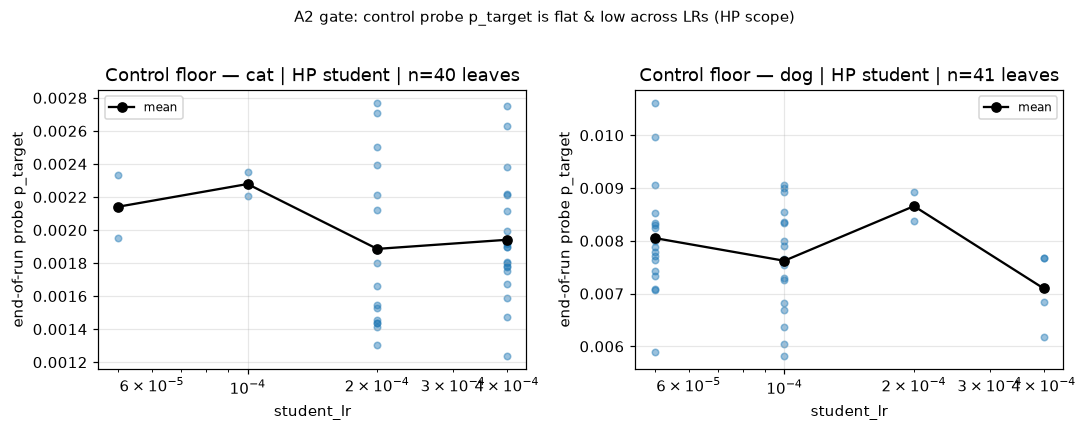

cat floor mean=0.0019 max=0.0028; dog floor mean=0.0078 max=0.0106; dog/cat mean ratio ≈ 4.00×


In [7]:
ctrl = eor_ctrl.copy()
print(f"HP control leaves: {len(ctrl)}")
floor = (
    ctrl.groupby(["animal", "student_lr"], observed=True)["p_target"]
    .agg(["mean", "median", "max", "count"])
    .reset_index()
)
print("End-of-run control probe p_target by animal × lr:")
display(floor)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=False)
for ax, animal in zip(axes, ["cat", "dog"]):
    sub = ctrl[ctrl["animal"] == animal]
    means = sub.groupby("student_lr")["p_target"].mean().sort_index()
    ax.scatter(sub["student_lr"], sub["p_target"], alpha=0.45, s=18)
    ax.plot(means.index, means.values, "k-o", lw=1.5, label="mean")
    ax.set_xscale("log")
    ax.set_title(f"Control floor — {animal} | HP student | n={len(sub)} leaves")
    ax.set_xlabel("student_lr")
    ax.set_ylabel("end-of-run probe p_target")
    ax.legend(fontsize=8)
fig.suptitle(
    "A2 gate: control probe p_target is flat & low across LRs (HP scope)",
    y=1.02, fontsize=10,
)
plt.tight_layout()
plt.show()

cat_mean = float(ctrl.loc[ctrl["animal"] == "cat", "p_target"].mean())
dog_mean = float(ctrl.loc[ctrl["animal"] == "dog", "p_target"].mean())
cat_max = float(ctrl.loc[ctrl["animal"] == "cat", "p_target"].max())
dog_max = float(ctrl.loc[ctrl["animal"] == "dog", "p_target"].max())
print(
    f"cat floor mean={cat_mean:.4f} max={cat_max:.4f}; "
    f"dog floor mean={dog_mean:.4f} max={dog_max:.4f}; "
    f"dog/cat mean ratio ≈ {dog_mean / cat_mean:.2f}×"
)
print(
    "WARNING: dog floor is several× the cat floor, so raw p_target is NOT "
    "comparable across animals. Prefer within-animal comparisons."
)
CONTROL_FLOOR = ctrl.groupby("animal")["p_target"].mean().to_dict()


## 3. The HP surface — lr × (rank, α) money plot

End-of-run probe `p_target` on the A1-like same-init e1 surface, faceted by
animal × β. Cells average over available gseeds after `~diverged` filtering.
**These are probe-grade, not eval-grade.** Fixed `vmin/vmax` per animal because
dog scores sit on a lower scale than cat (control-floor asymmetry).


cat: vmin=0.000 vmax=0.268 (95th pct of end-of-run p_target)
dog: vmin=0.000 vmax=0.162 (95th pct of end-of-run p_target)


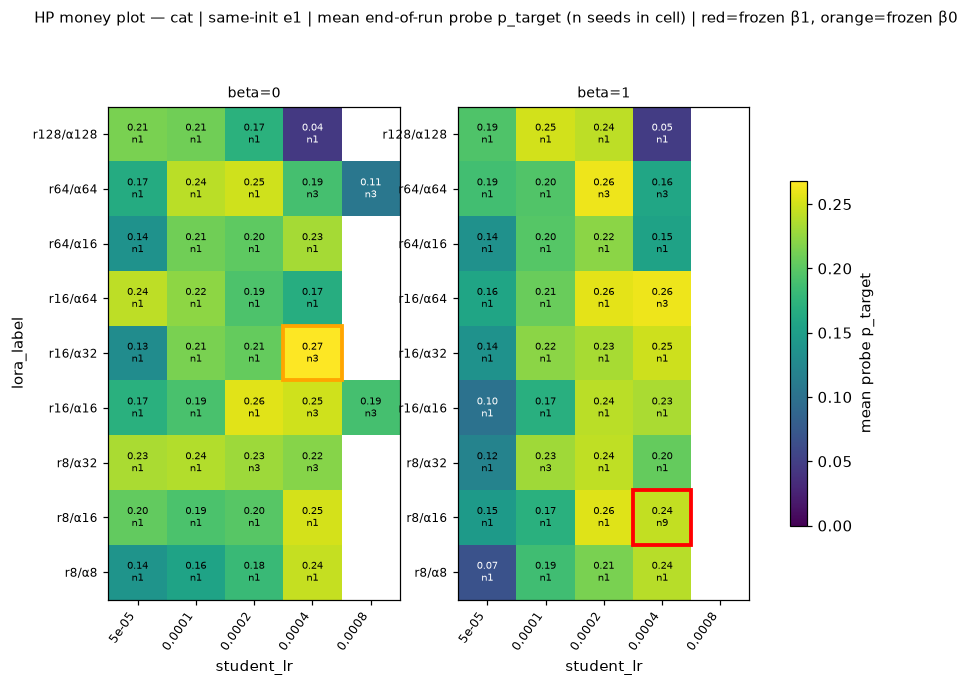

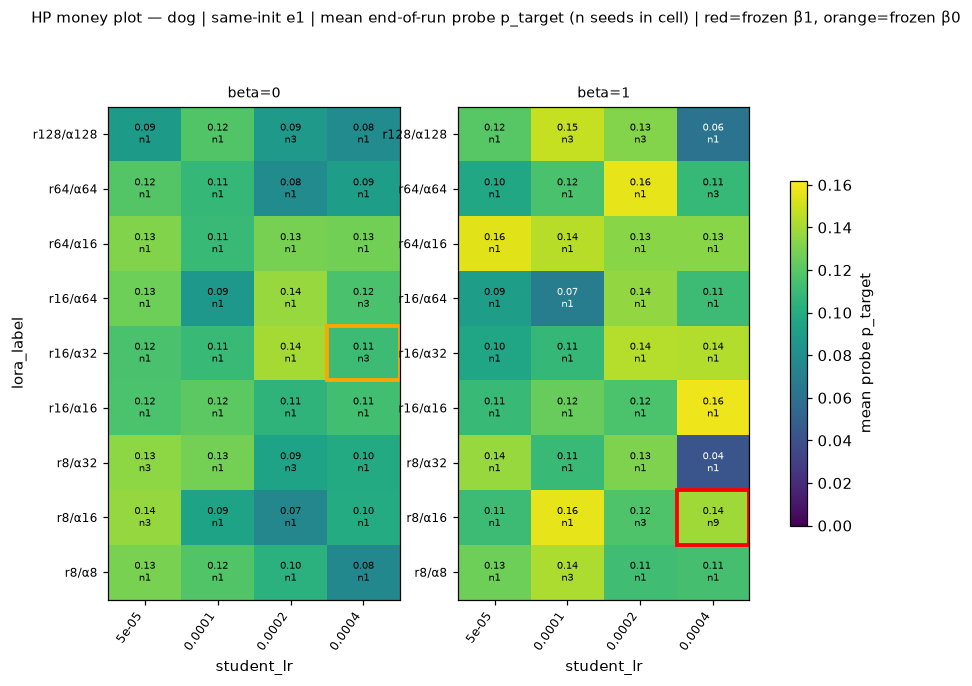

Aggregation: healthy same-init e1 treatments; n leaves=206; diverged filtered upstream. Highlight boxes mark freeze_report recipes.


In [8]:
# A1 money-plot surface: same-init, e1, healthy end-of-run treatments
money = eor_treat[
    eor_treat["teacher_base_label"].isna()
    & (eor_treat["num_epochs"] == 1)
].copy()
money = with_lora_label(money)

vmins, vmaxs = {}, {}
for animal in ["cat", "dog"]:
    s = money.loc[money["animal"] == animal, "p_target"]
    vmins[animal] = 0.0
    vmaxs[animal] = float(np.nanpercentile(s, 95))
    print(f"{animal}: vmin={vmins[animal]:.3f} vmax={vmaxs[animal]:.3f} "
          f"(95th pct of end-of-run p_target)")

fr1 = freeze["frozen"]["1"]["recipe"]
fr0 = freeze["frozen"]["0"]["recipe"]
frozen_label_b1 = f"r{fr1['lora_r']}/α{fr1['lora_alpha']}"
frozen_label_b0 = f"r{fr0['lora_r']}/α{fr0['lora_alpha']}"

for animal in ["cat", "dog"]:
    sub = money[money["animal"] == animal]
    fig = aplots.facet_grid_heatmaps(
        sub,
        row="lora_label",
        col="student_lr",
        val="p_target",
        col_facet="beta",
        agg="mean",
        show_n=True,
        cmap="viridis",
        vmin=vmins[animal],
        vmax=vmaxs[animal],
        orders={
            "student_lr": sorted(sub["student_lr"].unique()),
            "beta": [0.0, 1.0],
        },
        highlight=[
            {
                "lora_label": frozen_label_b1,
                "student_lr": fr1["lr"],
                "beta": 1.0,
                "color": "red",
                "lw": 2.5,
            },
            {
                "lora_label": frozen_label_b0,
                "student_lr": fr0["lr"],
                "beta": 0.0,
                "color": "orange",
                "lw": 2.5,
            },
        ],
        title=(
            f"HP money plot — {animal} | same-init e1 | mean end-of-run probe "
            f"p_target (n seeds in cell) | red=frozen β1, orange=frozen β0"
        ),
        cbar_label="mean probe p_target",
        panel_w=4.2,
        row_h=0.38,
        fmt="{:.2f}",
    )
    plt.show()

print(
    f"Aggregation: healthy same-init e1 treatments; n leaves={len(money)}; "
    f"diverged filtered upstream. Highlight boxes mark freeze_report recipes."
)


## 4. Is there an lr × α law?

Plot end-of-run probe `p_target` vs `log10(lr · α)`, coloured by rank. A monotone
“law” would show a rising Spearman; an **inverted-U / ridge** will drive the
correlation near zero even when the surface is highly structured. Headline =
the ridge plot, not the correlation.


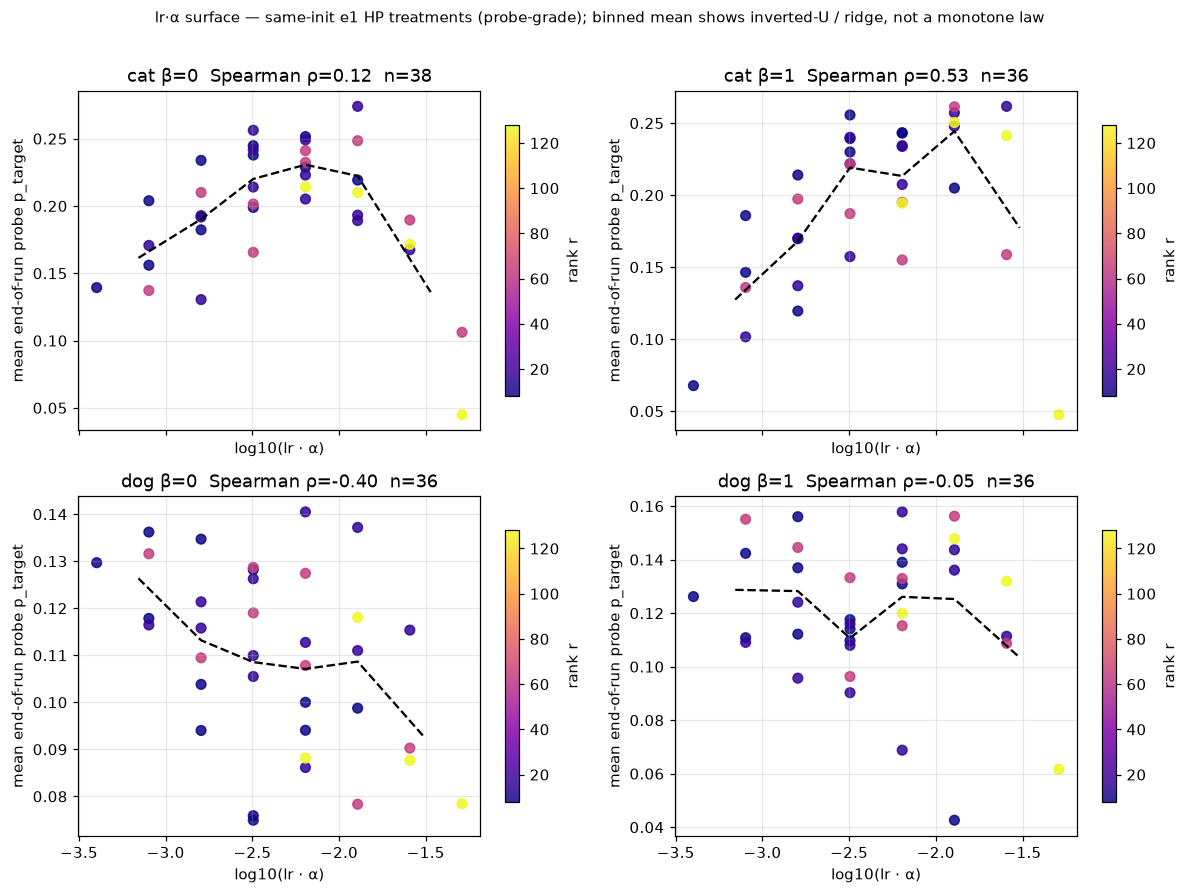

,animal,beta,n_recipes,spearman_p_target_vs_log10_lr_alpha
0,cat,0.0,38,0.116738
1,cat,1.0,36,0.533162
2,dog,0.0,36,-0.397094
3,dog,1.0,36,-0.048362


VERDICT: Spearman of p_target vs log10(lr·α) is non-monotone / near-zero for most (animal, β) cells. Do NOT report a plain correlation as the headline. This is a genuine partial non-replication of a monotone lr×α law: there is structure (inverted-U / collapse at the top corner), not a rising law.

cat β=1 r128a128:


,student_lora_r,student_lora_alpha,student_lr,p_target
32,128,128,0.00005,0.194448
33,128,128,0.00010,0.250437
34,128,128,0.00020,0.241217
35,128,128,0.00040,0.047578



cat β=1 r64a64:


,student_lora_r,student_lora_alpha,student_lr,p_target
28,64,64,0.00005,0.187175
29,64,64,0.00010,0.195015
30,64,64,0.00020,0.261339
31,64,64,0.00040,0.158702


In [9]:
ridge = money.copy()
ridge["lr_alpha"] = ridge["student_lr"] * ridge["student_lora_alpha"]
ridge["log10_lr_alpha"] = np.log10(ridge["lr_alpha"].astype(float))

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
corr_rows = []
for ax, (animal, beta) in zip(
    axes.ravel(),
    [("cat", 0.0), ("cat", 1.0), ("dog", 0.0), ("dog", 1.0)],
):
    sub = ridge[(ridge["animal"] == animal) & (ridge["beta"] == beta)]
    g = (
        sub.groupby(
            ["student_lora_r", "student_lora_alpha", "student_lr", "log10_lr_alpha"],
            as_index=False,
        )["p_target"].mean()
    )
    sc = ax.scatter(
        g["log10_lr_alpha"], g["p_target"],
        c=g["student_lora_r"], cmap="plasma", s=40, alpha=0.85,
    )
    if len(g) >= 4:
        bins = pd.cut(g["log10_lr_alpha"], bins=min(6, max(3, len(g) // 3)))
        bm = g.groupby(bins, observed=True)["p_target"].mean()
        bx = g.groupby(bins, observed=True)["log10_lr_alpha"].mean()
        ax.plot(bx.values, bm.values, "k--", lw=1.5, label="binned mean")
    if len(g) >= 3:
        rho = float(spearmanr(g["log10_lr_alpha"], g["p_target"]).statistic)
    else:
        rho = float("nan")
    corr_rows.append({
        "animal": animal, "beta": beta, "n_recipes": len(g),
        "spearman_p_target_vs_log10_lr_alpha": rho,
    })
    ax.set_title(f"{animal} β={beta:g}  Spearman ρ={rho:.2f}  n={len(g)}")
    ax.set_xlabel("log10(lr · α)")
    ax.set_ylabel("mean end-of-run probe p_target")
    fig.colorbar(sc, ax=ax, shrink=0.8, label="rank r")

fig.suptitle(
    "lr·α surface — same-init e1 HP treatments (probe-grade); "
    "binned mean shows inverted-U / ridge, not a monotone law",
    y=1.01, fontsize=10,
)
plt.tight_layout()
plt.show()

corr_tbl = pd.DataFrame(corr_rows)
display(corr_tbl)
print(
    "VERDICT: Spearman of p_target vs log10(lr·α) is non-monotone / near-zero "
    "for most (animal, β) cells. Do NOT report a plain correlation as the "
    "headline. This is a genuine partial non-replication of a monotone lr×α law: "
    "there is structure (inverted-U / collapse at the top corner), not a rising law."
)

ex = (ridge[(ridge["animal"] == "cat") & (ridge["beta"] == 1.0)]
      .groupby(["student_lora_r", "student_lora_alpha", "student_lr"], as_index=False)
      ["p_target"].mean())
for r, a in [(128, 128), (64, 64)]:
    sub = ex[(ex["student_lora_r"] == r) & (ex["student_lora_alpha"] == a)].sort_values("student_lr")
    print(f"\ncat β=1 r{r}a{a}:")
    display(sub)


## 5. Divergence and instability map

`diverged` semantics (`DIVERGENCE_PPL_FACTOR`): a leaf is flagged when any probe
metric is non-finite **or** any later `ppl` exceeds **10×** that leaf’s **own
first** probe ppl. Flag is relative, not absolute.


DIVERGENCE_PPL_FACTOR = 10.0
Diverged leaves in HP scope: 7 / 791
Diverged leaves in full tree: 8 / 1073
Diverged-leaf table (HP scope):


,animal,beta,student_lr,num_epochs,student_lora_r,student_lora_alpha,gseed,p_target,ppl,gkd_tag,is_control
115,cat,0.0,0.0008,10.0,64,64,0,0.173973,89.658875,lmb1.0_b0.0_lora_lr8e-4_e10_r64a64,False
116,cat,0.0,0.0008,10.0,64,64,1,0.087414,90.482033,lmb1.0_b0.0_lora_lr8e-4_e10_r64a64,False
117,cat,0.0,0.0008,10.0,64,64,2,0.075017,79.250931,lmb1.0_b0.0_lora_lr8e-4_e10_r64a64,False
127,cat,0.0,0.0008,3.0,64,64,0,0.022391,112.587112,lmb1.0_b0.0_lora_lr8e-4_e3_r64a64,False
133,cat,0.0,0.0008,5.0,64,64,0,0.057630,89.427116,lmb1.0_b0.0_lora_lr8e-4_e5_r64a64,False
135,cat,0.0,0.0008,5.0,64,64,2,0.023658,113.769203,lmb1.0_b0.0_lora_lr8e-4_e5_r64a64,False
601,dog,1.0,0.0002,10.0,128,128,1,0.126351,60.040413,lmb1.0_b1.0_lora_lr2e-4_e10_r128a128,False


A1 money-grid (healthy) ppl: median=57.7 max=131.3
Nothing like the 2.5e26 ppl catastrophic cliff from cats_wide.


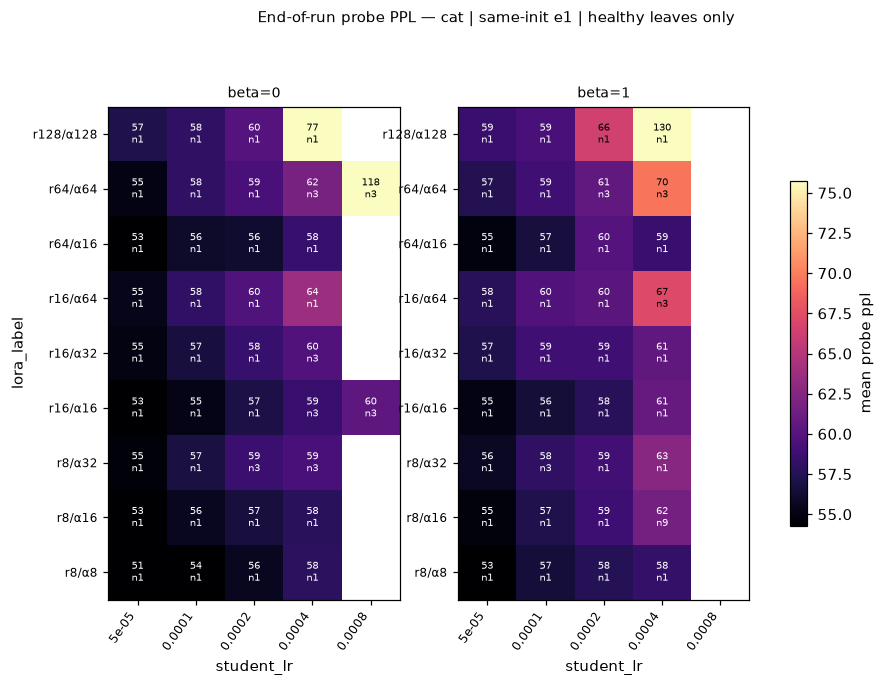

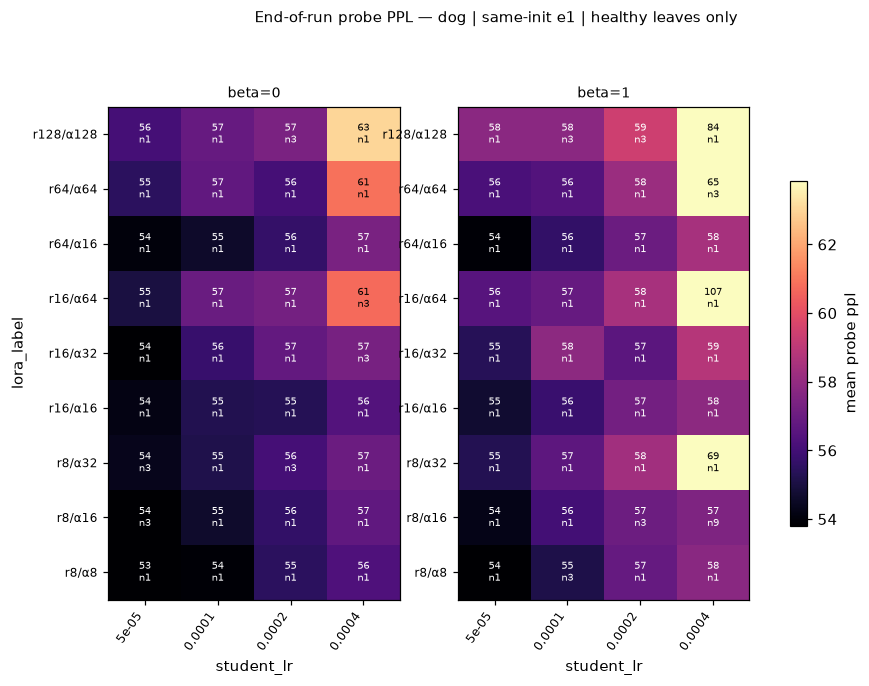

In [10]:
print(f"DIVERGENCE_PPL_FACTOR = {DIVERGENCE_PPL_FACTOR}")
hp_eor_raw = end_of_run_probes(probes)
n_div = int(hp_eor_raw["diverged"].sum())
n_leaves = len(hp_eor_raw)
print(f"Diverged leaves in HP scope: {n_div} / {n_leaves}")
full_raw = end_of_run_probes(probes_all)
print(f"Diverged leaves in full tree: {int(full_raw['diverged'].sum())} / {len(full_raw)}")

div_tbl = hp_eor_raw[hp_eor_raw['diverged']][
    ["animal", "beta", "student_lr", "num_epochs", "student_lora_r",
     "student_lora_alpha", "gseed", "p_target", "ppl", "gkd_tag", "is_control"]
].sort_values(["animal", "student_lora_r", "student_lr"])
print("Diverged-leaf table (HP scope):")
display(div_tbl)

ppl_grid = money.copy()
a1_ppl_max = float(ppl_grid["ppl"].max())
a1_ppl_med = float(ppl_grid["ppl"].median())
print(f"A1 money-grid (healthy) ppl: median={a1_ppl_med:.1f} max={a1_ppl_max:.1f}")
print("Nothing like the 2.5e26 ppl catastrophic cliff from cats_wide.")

for animal in ["cat", "dog"]:
    sub = ppl_grid[ppl_grid["animal"] == animal]
    fig = aplots.facet_grid_heatmaps(
        sub,
        row="lora_label", col="student_lr", val="ppl", col_facet="beta",
        agg="mean", show_n=True, cmap="magma",
        vmin=float(sub["ppl"].quantile(0.05)),
        vmax=float(sub["ppl"].quantile(0.95)),
        orders={
            "student_lr": sorted(sub["student_lr"].unique()),
            "beta": [0.0, 1.0],
        },
        title=f"End-of-run probe PPL — {animal} | same-init e1 | healthy leaves only",
        cbar_label="mean probe ppl", panel_w=4.2, row_h=0.38, fmt="{:.0f}",
    )
    plt.show()


## 6. β = 0 vs β = 1

Paired on `(animal, r, α, lr)`, same-init, e1. Per the experiment plan §3.1 this
β axis is unexplored in the literature — a well-powered **near-null** is a real
result.


Paired n=72; mean(β1−β0)=0.0022; β1>β0 in 52.8% of pairs
Sign test (H1: delta>0): n_pos=38 / 72  frac=0.528  p=0.362


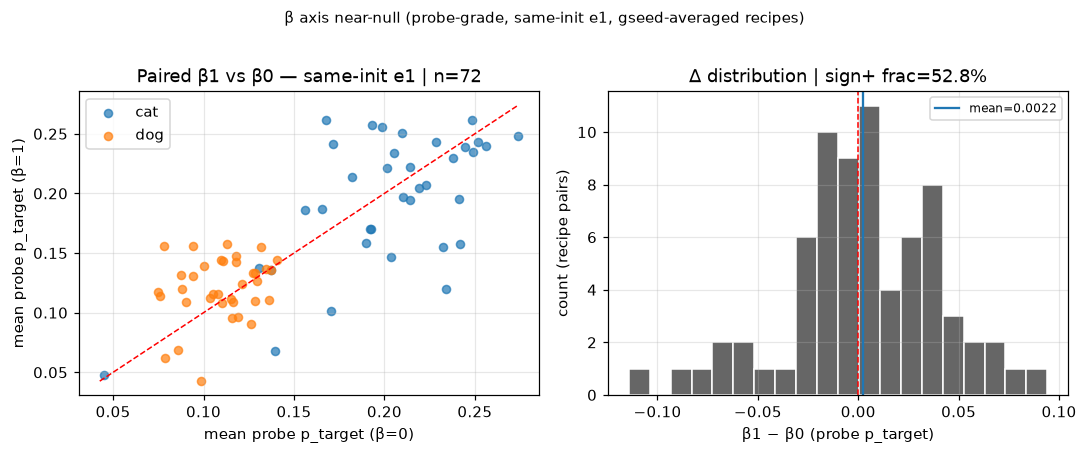

In [11]:
bframe = (
    money.groupby(
        ["animal", "student_lora_r", "student_lora_alpha", "student_lr", "beta"],
        as_index=False,
    )["p_target"].mean()
)
wide = bframe.pivot_table(
    index=["animal", "student_lora_r", "student_lora_alpha", "student_lr"],
    columns="beta",
    values="p_target",
).dropna()
wide = wide.rename(columns={0.0: "beta0", 1.0: "beta1"}).reset_index()
wide["delta_b1_minus_b0"] = wide["beta1"] - wide["beta0"]
n_pairs = len(wide)
mean_d = float(wide["delta_b1_minus_b0"].mean())
frac_pos = float((wide["delta_b1_minus_b0"] > 0).mean())
st = sign_test(list(wide["delta_b1_minus_b0"]), 0.0, "greater")
print(f"Paired n={n_pairs}; mean(β1−β0)={mean_d:.4f}; β1>β0 in {frac_pos:.1%} of pairs")
print(f"Sign test (H1: delta>0): n_pos={st.n_positive} / {st.n_effective}  "
      f"frac={st.frac_positive:.3f}  p={st.p_value:.4g}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
for animal, color in [("cat", "C0"), ("dog", "C1")]:
    s = wide[wide["animal"] == animal]
    ax.scatter(s["beta0"], s["beta1"], s=28, alpha=0.7, label=animal, c=color)
lo = float(min(wide["beta0"].min(), wide["beta1"].min()))
hi = float(max(wide["beta0"].max(), wide["beta1"].max()))
ax.plot([lo, hi], [lo, hi], "r--", lw=1)
ax.set_xlabel("mean probe p_target (β=0)")
ax.set_ylabel("mean probe p_target (β=1)")
ax.set_title(f"Paired β1 vs β0 — same-init e1 | n={n_pairs}")
ax.legend()

axes[1].hist(wide["delta_b1_minus_b0"], bins=20, color="0.4", edgecolor="white")
axes[1].axvline(0, color="red", ls="--", lw=1)
axes[1].axvline(mean_d, color="C0", lw=1.5, label=f"mean={mean_d:.4f}")
axes[1].set_xlabel("β1 − β0 (probe p_target)")
axes[1].set_ylabel("count (recipe pairs)")
axes[1].set_title(f"Δ distribution | sign+ frac={frac_pos:.1%}")
axes[1].legend(fontsize=8)
fig.suptitle(
    "β axis near-null (probe-grade, same-init e1, gseed-averaged recipes)",
    y=1.02, fontsize=10,
)
plt.tight_layout()
plt.show()


## 7. Dose ladder and probe trajectories

Dose response across `num_epochs ∈ {0.5, 1, 3, 5, 10}` on the HP surface, plus
peak-then-decay quantification (findings 5–6).


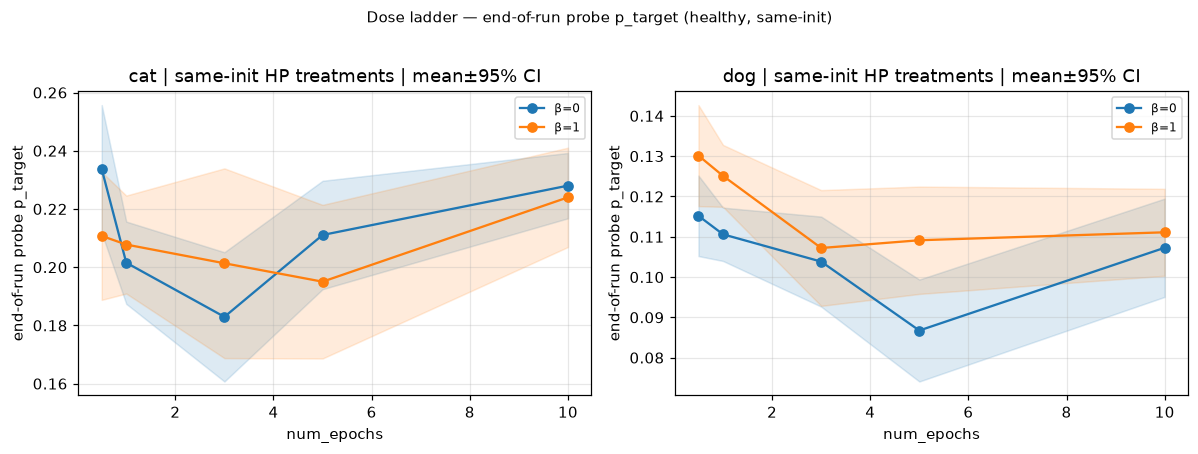

Mean end-of-run p_target by animal × β × epochs:


num_epochs    0.5    1.0    3.0    5.0    10.0
animal beta                                   
cat    0.0   0.234  0.202  0.183  0.211  0.228
       1.0   0.211  0.208  0.201  0.195  0.224
dog    0.0   0.115  0.111  0.104  0.087  0.107
       1.0   0.130  0.125  0.107  0.109  0.111

In [12]:
dose = eor_treat[eor_treat["teacher_base_label"].isna()].copy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, animal in zip(axes, ["cat", "dog"]):
    sub = dose[dose["animal"] == animal]
    drawn = aplots.dose_response(
        ax, sub, x="num_epochs", y="p_target", group="beta",
        order=[0.0, 1.0],
        labels={0.0: "β=0", 1.0: "β=1"},
        ci=True,
    )
    ax.set_title(f"{animal} | same-init HP treatments | mean±95% CI")
    ax.set_xlabel("num_epochs")
    ax.set_ylabel("end-of-run probe p_target")
    if drawn:
        ax.legend(fontsize=8)
fig.suptitle(
    "Dose ladder — end-of-run probe p_target (healthy, same-init)",
    y=1.02, fontsize=10,
)
plt.tight_layout()
plt.show()

means = (
    dose.groupby(["animal", "beta", "num_epochs"])["p_target"]
    .mean()
    .unstack("num_epochs")
)
print("Mean end-of-run p_target by animal × β × epochs:")
display(means.round(3))


Treatment leaves ending <80% of own peak: 402 / 703 = 57.2%
Median peak p_target: 0.194


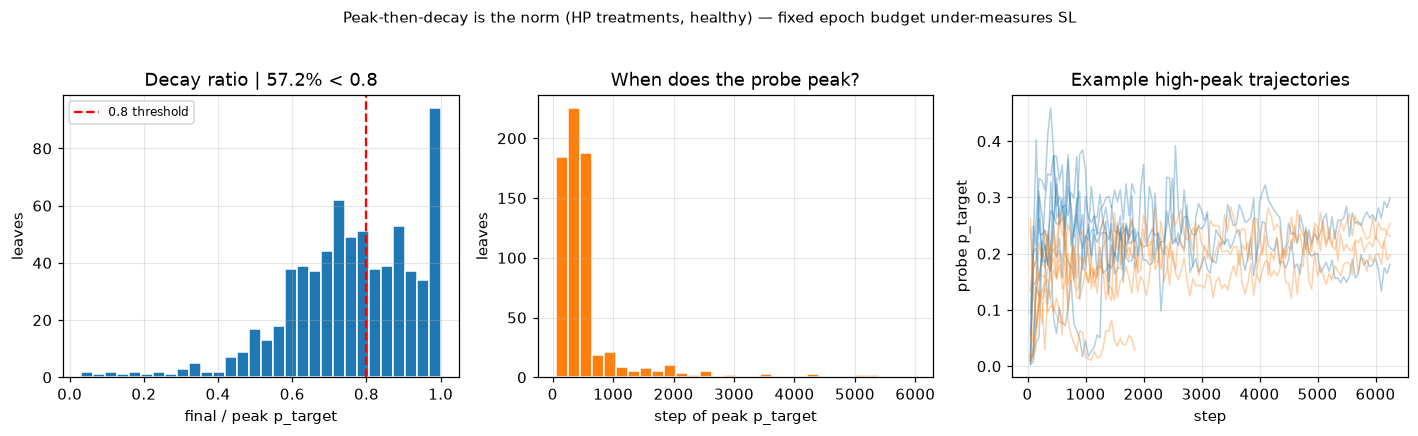

In [13]:
# Peak-then-decay quantification
pt = peak_treat[["run_dir", "p_target", "step"]].rename(
    columns={"p_target": "peak_p_target", "step": "peak_step"}
)
merged = eor_treat.merge(pt, on="run_dir", how="inner")
merged["final_over_peak"] = merged["p_target"] / merged["peak_p_target"].replace(0, np.nan)
merged["below_80pct_peak"] = merged["final_over_peak"] < 0.8
frac_decay = float(merged["below_80pct_peak"].mean())
med_peak = float(merged["peak_p_target"].median())
print(
    f"Treatment leaves ending <80% of own peak: "
    f"{merged['below_80pct_peak'].sum()} / {len(merged)} = {frac_decay:.1%}"
)
print(f"Median peak p_target: {med_peak:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].hist(merged["final_over_peak"].dropna(), bins=30, color="C0", edgecolor="white")
axes[0].axvline(0.8, color="red", ls="--", label="0.8 threshold")
axes[0].set_xlabel("final / peak p_target")
axes[0].set_ylabel("leaves")
axes[0].set_title(f"Decay ratio | {frac_decay:.1%} < 0.8")
axes[0].legend(fontsize=8)

axes[1].hist(merged["peak_step"].dropna(), bins=30, color="C1", edgecolor="white")
axes[1].set_xlabel("step of peak p_target")
axes[1].set_ylabel("leaves")
axes[1].set_title("When does the probe peak?")

traj = probes_h[~probes_h["is_control"]].copy()
ax = axes[2]
for animal, color in [("cat", "C0"), ("dog", "C1")]:
    sub = merged[merged["animal"] == animal].nlargest(8, "peak_p_target")
    for rd in sub["run_dir"]:
        t = traj[traj["run_dir"] == rd].sort_values("step")
        ax.plot(t["step"], t["p_target"], color=color, alpha=0.35, lw=1)
ax.set_xlabel("step")
ax.set_ylabel("probe p_target")
ax.set_title("Example high-peak trajectories")
fig.suptitle(
    "Peak-then-decay is the norm (HP treatments, healthy) — "
    "fixed epoch budget under-measures SL",
    y=1.03, fontsize=10,
)
plt.tight_layout()
plt.show()


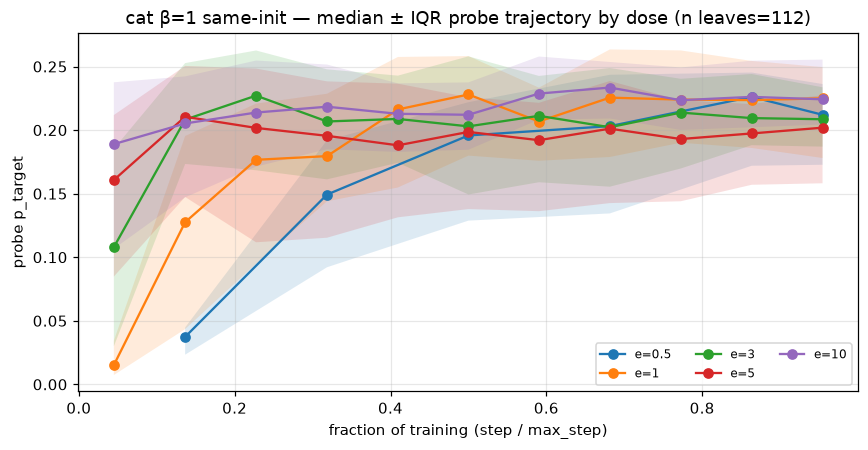

In [14]:
# Trajectory median ± IQR bands by dose (cat β=1 same-init)
ex_traj = probes_h[
    (~probes_h["is_control"])
    & probes_h["teacher_base_label"].isna()
    & (probes_h["animal"] == "cat")
    & (probes_h["beta"] == 1.0)
].copy()
ex_traj["step_frac"] = ex_traj.groupby("run_dir")["step"].transform(
    lambda s: s / s.max() if s.max() else np.nan
)

fig, ax = plt.subplots(figsize=(8, 4.2))
epochs_show = sorted(ex_traj["num_epochs"].unique())
for ep in epochs_show:
    sub = ex_traj[ex_traj["num_epochs"] == ep].dropna(subset=["step_frac", "p_target"]).copy()
    if sub.empty:
        continue
    bins = np.linspace(0, 1, 12)
    sub["bin"] = pd.cut(sub["step_frac"], bins=bins, include_lowest=True)
    g = sub.groupby("bin", observed=True)["p_target"]
    med = g.median()
    q1 = g.quantile(0.25)
    q3 = g.quantile(0.75)
    x = np.array([iv.mid for iv in med.index])
    ax.plot(x, med.values, marker="o", label=f"e={ep:g}")
    ax.fill_between(x, q1.values, q3.values, alpha=0.15)
ax.set_xlabel("fraction of training (step / max_step)")
ax.set_ylabel("probe p_target")
ax.set_title(
    "cat β=1 same-init — median ± IQR probe trajectory by dose "
    f"(n leaves={ex_traj['run_dir'].nunique()})"
)
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()


## 8. Emergence timing — and why this tree cannot resolve it

Two **novel** operationalisations (experiment plan §6 / §7 item 4 — both are
notebook-local, neither is a pipeline SSOT metric):

1. **Separation step** — first probe step where `p_target` exceeds the matched
   control's *per-step* mean + 2 SD. This is the E1 rule from the experiment plan.
2. **Half-peak step** (`t50`) — first probe step at which a leaf reaches ≥ 50% of
   its **own** trajectory maximum. This is the fraction-of-peak alternative listed
   in §7 item 4.

The headline of this section is a **measurement-resolution result, not a timing
result**. The probe cadence is 50 steps and one epoch is 625 steps, so the first
observation lands at ~8% of an epoch. By that first probe the median treatment
leaf already sits at `p_target` ≈ 0.03–0.04 against a control floor of 0.002
(cat) / 0.008 (dog) — an order of magnitude above the floor. Criterion 1
therefore fires at the **first probe** for essentially every leaf and is
**right-censored**: it reports "step 50" because that is the earliest observable
step, not because that is when the trait appeared.

So: SL under on-policy GKD is installed *earlier than this instrumentation can
see*. Resolving it requires a denser probe cadence (E9's checkpoint work), not a
different threshold. `t50` is reported because it is **not** censored and still
carries a usable dose/β signal.


Probe cadence: every 50 steps; first observable step = 50
Control per-step mean+2SD threshold: cat=0.0027, dog=0.0109

Separated from control: 703 / 703 (100.0%); of those, 644 (91.6%) separate at the FIRST probe (step 50).
=> Criterion 1 is RIGHT-CENSORED: SL is already present at the earliest observable step, so this tree bounds emergence at <= 50 steps rather than measuring it.


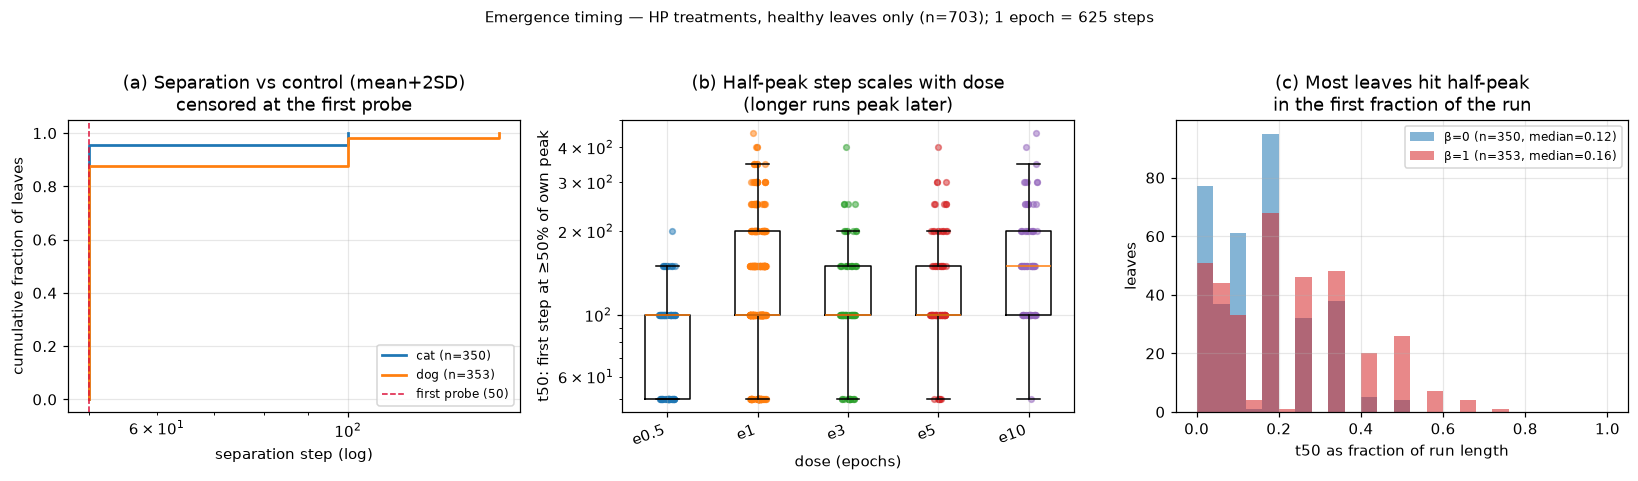

Half-peak step (t50) by animal × β × dose — the uncensored view:


median   mean  count
animal beta num_epochs                      
cat    0.0  0.5          100.0   81.2     24
            1.0          100.0  131.7     90
            3.0          100.0  108.7     23
            5.0          100.0  131.8     22
            10.0         150.0  157.1     21
       1.0  0.5          100.0  119.4     18
            1.0          200.0  201.5     98
            3.0          150.0  166.7     18
            5.0          150.0  161.1     18
            10.0         200.0  211.1     18
dog    0.0  0.5           50.0   73.8     21
            1.0          100.0   91.3     86
            3.0          100.0   97.6     21
            5.0          100.0  121.4     21
            10.0         100.0  154.8     21
       1.0  0.5          100.0   90.5     21
            1.0          125.0  136.0    100
            3.0          100.0  111.9     21
            5.0          100.0  135.7     21
            10.0         150.0  160.0     20

In [15]:
# Criterion 1 (E1 rule): control per-step mean + 2 SD, evaluated per (animal, step).
ctrl_traj = probes_h[probes_h["is_control"]]
ctrl_step = (
    ctrl_traj.groupby(["animal", "step"])["p_target"]
    .agg(["mean", "std"])
    .reset_index()
)
ctrl_step["sep_threshold"] = ctrl_step["mean"] + 2.0 * ctrl_step["std"].fillna(0.0)

treat_traj = probes_h[~probes_h["is_control"]].merge(
    ctrl_step[["animal", "step", "sep_threshold"]], on=["animal", "step"], how="left"
)
FIRST_STEP = int(treat_traj["step"].min())
print(f"Probe cadence: every {FIRST_STEP} steps; first observable step = {FIRST_STEP}")
print(
    "Control per-step mean+2SD threshold: "
    + ", ".join(
        f"{a}={ctrl_step.loc[ctrl_step['animal'] == a, 'sep_threshold'].mean():.4f}"
        for a in sorted(ctrl_step["animal"].unique())
    )
)

records = []
for rd, g in treat_traj.groupby("run_dir"):
    g = g.sort_values("step")
    peak = float(g["p_target"].max())
    sep_hit = g[g["p_target"] > g["sep_threshold"]]
    t50_hit = g[g["p_target"] >= 0.5 * peak]
    records.append({
        "run_dir": rd,
        "animal": g["animal"].iloc[0],
        "beta": float(g["beta"].iloc[0]),
        "student_lora_r": g["student_lora_r"].iloc[0],
        "student_lr": float(g["student_lr"].iloc[0]),
        "num_epochs": float(g["num_epochs"].iloc[0]),
        "n_probes": len(g),
        "separated": len(sep_hit) > 0,
        "separation_step": int(sep_hit["step"].iloc[0]) if len(sep_hit) else np.nan,
        "t50_step": int(t50_hit["step"].iloc[0]) if len(t50_hit) else np.nan,
        "peak_p_target": peak,
    })
emerge = pd.DataFrame(records)

n_sep = int(emerge["separated"].sum())
at_first = int((emerge["separation_step"] == FIRST_STEP).sum())
print(
    f"\nSeparated from control: {n_sep} / {len(emerge)} ({n_sep / len(emerge):.1%}); "
    f"of those, {at_first} ({at_first / max(n_sep, 1):.1%}) separate at the FIRST "
    f"probe (step {FIRST_STEP})."
)
print(
    "=> Criterion 1 is RIGHT-CENSORED: SL is already present at the earliest "
    "observable step, so this tree bounds emergence at "
    f"<= {FIRST_STEP} steps rather than measuring it."
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) ECDF of separation step — shows the censoring pile-up at step 50.
ax = axes[0]
for animal, colr in zip(["cat", "dog"], ["C0", "C1"]):
    v = np.sort(emerge.loc[emerge["animal"] == animal, "separation_step"].dropna())
    if len(v):
        ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post",
                label=f"{animal} (n={len(v)})", color=colr, lw=1.8)
ax.axvline(FIRST_STEP, color="crimson", ls="--", lw=1,
           label=f"first probe ({FIRST_STEP})")
ax.set_xscale("log")
ax.set_xlabel("separation step (log)")
ax.set_ylabel("cumulative fraction of leaves")
ax.set_title("(a) Separation vs control (mean+2SD)\ncensored at the first probe")
ax.legend(fontsize=8)

# (b) Half-peak step by dose — NOT censored, so it carries signal.
ax = axes[1]
doses = sorted(emerge["num_epochs"].dropna().unique())
groups = [emerge.loc[emerge["num_epochs"] == d, "t50_step"].dropna().tolist()
          for d in doses]
aplots.strip_box(ax, groups, [f"e{d:g}" for d in doses])
ax.set_yscale("log")
ax.set_ylabel("t50: first step at ≥50% of own peak")
ax.set_xlabel("dose (epochs)")
ax.set_title("(b) Half-peak step scales with dose\n(longer runs peak later)")

# (c) t50 as a FRACTION of each leaf's run length — dose-normalised.
ax = axes[2]
frac = emerge.dropna(subset=["t50_step"]).copy()
frac["t50_frac"] = frac["t50_step"] / (frac["num_epochs"] * 625.0)
for beta, colr in zip([0.0, 1.0], ["C0", "C3"]):
    v = frac.loc[frac["beta"] == beta, "t50_frac"].dropna()
    ax.hist(v, bins=np.linspace(0, 1, 26), alpha=0.55, color=colr,
            label=f"β={beta:g} (n={len(v)}, median={v.median():.2f})")
ax.set_xlabel("t50 as fraction of run length")
ax.set_ylabel("leaves")
ax.set_title("(c) Most leaves hit half-peak\nin the first fraction of the run")
ax.legend(fontsize=8)

fig.suptitle(
    "Emergence timing — HP treatments, healthy leaves only "
    f"(n={len(emerge)}); 1 epoch = 625 steps",
    y=1.03, fontsize=10,
)
plt.tight_layout()
plt.show()

print("Half-peak step (t50) by animal × β × dose — the uncensored view:")
display(
    emerge.groupby(["animal", "beta", "num_epochs"])["t50_step"]
    .agg(["median", "mean", "count"])
    .round(1)
)


## 9. Capability guardrail

**This tree has no `bench_*` columns** — the capability guardrail is
**perplexity-ratio only**. Join to eval-grade test Δ is sparse; treat correlations
as weak / underpowered.


HP capability treatment rows: 371
perplexity_ratio: mean=1.654 median=1.591 [1.451, 1.835] 10–90%
bench_* columns present: NONE
Joined capability ↔ test Δ rows: 41
Spearman(ppl_ratio, test Δ) = 0.354 (n=41)


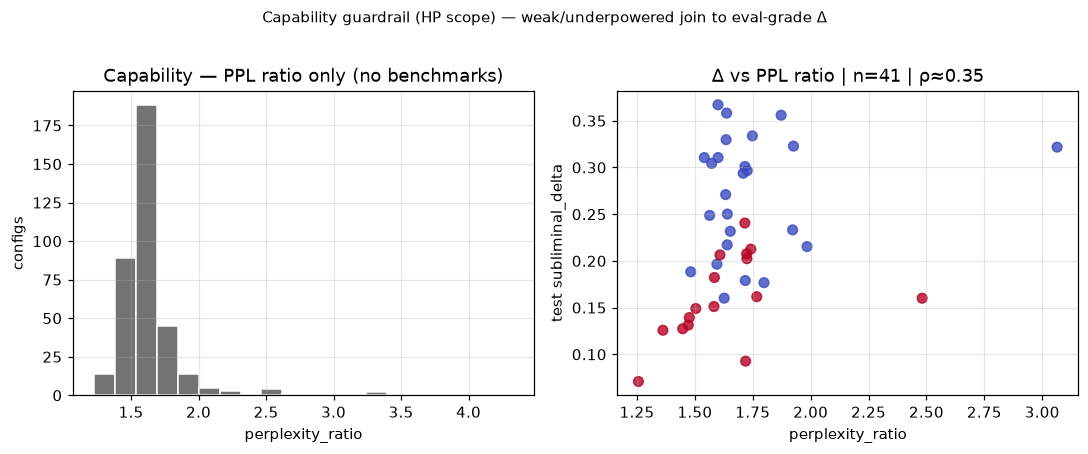

INTERPRETATION: typical perplexity_ratio ≈ 1.5–1.6. Stronger SL comes with somewhat worse PPL in the small joined set — report n and do not headline this.


In [16]:
cap_t = cap[~cap["is_control"]].copy()
print(f"HP capability treatment rows: {len(cap_t)}")
print(
    f"perplexity_ratio: mean={cap_t['perplexity_ratio'].mean():.3f} "
    f"median={cap_t['perplexity_ratio'].median():.3f} "
    f"[{cap_t['perplexity_ratio'].quantile(0.1):.3f}, "
    f"{cap_t['perplexity_ratio'].quantile(0.9):.3f}] 10–90%"
)
bench_cols = [c for c in cap.columns if c.startswith("bench_")]
print(f"bench_* columns present: {bench_cols if bench_cols else 'NONE'}")

dtest = subliminal_delta(pref)
dtest = dtest[dtest["set"] == "test"].copy()
join_keys = [
    "animal", "model", "gkd_tag", "teacher_cross_init", "teacher_base_label",
]
cap_avg = (
    cap_t.groupby(
        ["animal", "model", "gkd_tag", "teacher_cross_init", "teacher_base_label"],
        dropna=False,
        as_index=False,
    )["perplexity_ratio"].mean()
)
joined = dtest.merge(cap_avg, on=join_keys, how="inner")
print(f"Joined capability ↔ test Δ rows: {len(joined)}")
if len(joined) >= 3:
    rho = float(spearmanr(joined["perplexity_ratio"], joined["subliminal_delta"]).statistic)
    print(f"Spearman(ppl_ratio, test Δ) = {rho:.3f} (n={len(joined)})")
else:
    rho = float("nan")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(cap_t["perplexity_ratio"].dropna(), bins=20, color="0.45", edgecolor="white")
axes[0].set_xlabel("perplexity_ratio")
axes[0].set_ylabel("configs")
axes[0].set_title("Capability — PPL ratio only (no benchmarks)")

if len(joined):
    axes[1].scatter(
        joined["perplexity_ratio"], joined["subliminal_delta"],
        c=joined["animal"].map({"cat": 0, "dog": 1}), cmap="coolwarm",
        s=40, alpha=0.8,
    )
    axes[1].set_xlabel("perplexity_ratio")
    axes[1].set_ylabel("test subliminal_delta")
    axes[1].set_title(f"Δ vs PPL ratio | n={len(joined)} | ρ≈{rho:.2f}")
else:
    axes[1].text(0.5, 0.5, "no join rows", ha="center", va="center")
fig.suptitle(
    "Capability guardrail (HP scope) — weak/underpowered join to eval-grade Δ",
    y=1.02, fontsize=10,
)
plt.tight_layout()
plt.show()
print(
    "INTERPRETATION: typical perplexity_ratio ≈ 1.5–1.6. "
    "Stronger SL comes with somewhat worse PPL in the small joined set — "
    "report n and do not headline this."
)


## 10. Specificity — forced choice

Forced-choice `target_share_mean` on HP treatments (target candidate only).


HP FC target rows: 371


,mean,median,std,count
animal,,,,
cat,0.817,0.851,0.106,187
dog,0.810,0.803,0.048,184


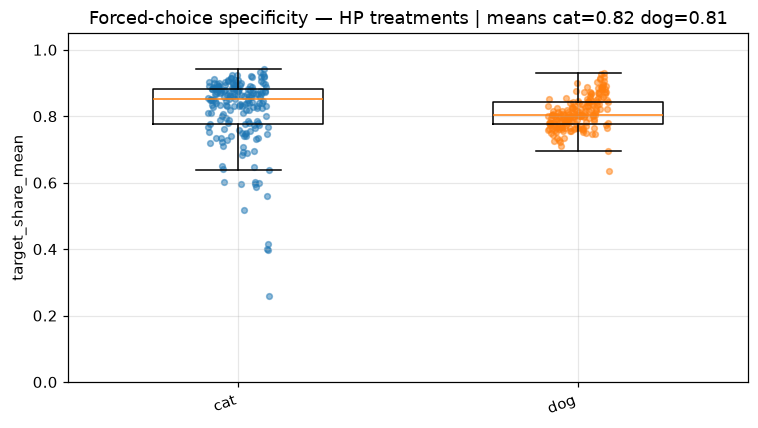

High target_share (≈0.8+) indicates the preference is for the *target* animal in the candidate set, not a generic animal bump.


In [17]:
fc_t = fc[(~fc["is_control"]) & fc["is_target"]].copy()
print(f"HP FC target rows: {len(fc_t)}")
summary = (
    fc_t.groupby("animal")["target_share_mean"]
    .agg(["mean", "median", "std", "count"])
    .round(3)
)
display(summary)

fig, ax = plt.subplots(figsize=(7, 4))
groups = [
    fc_t.loc[fc_t["animal"] == a, "target_share_mean"].dropna().tolist()
    for a in ["cat", "dog"]
]
aplots.strip_box(ax, groups, ["cat", "dog"], colors=["C0", "C1"])
ax.set_ylabel("target_share_mean")
ax.set_title(
    f"Forced-choice specificity — HP treatments | "
    f"means cat={summary.loc['cat','mean']:.2f} dog={summary.loc['dog','mean']:.2f}"
)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()
print(
    "High target_share (≈0.8+) indicates the preference is for the *target* animal "
    "in the candidate set, not a generic animal bump."
)


## 11. Eval-grade confirmation

`subliminal_delta_ci` on covered configs, prompt-set generalization ladder,
sign test, and reconciliation against `freeze_report.json`.


subliminal_delta_ci rows (all sets): 348
sets present: ['consensus', 'dislike', 'favorite', 'register', 'test', 'validation']


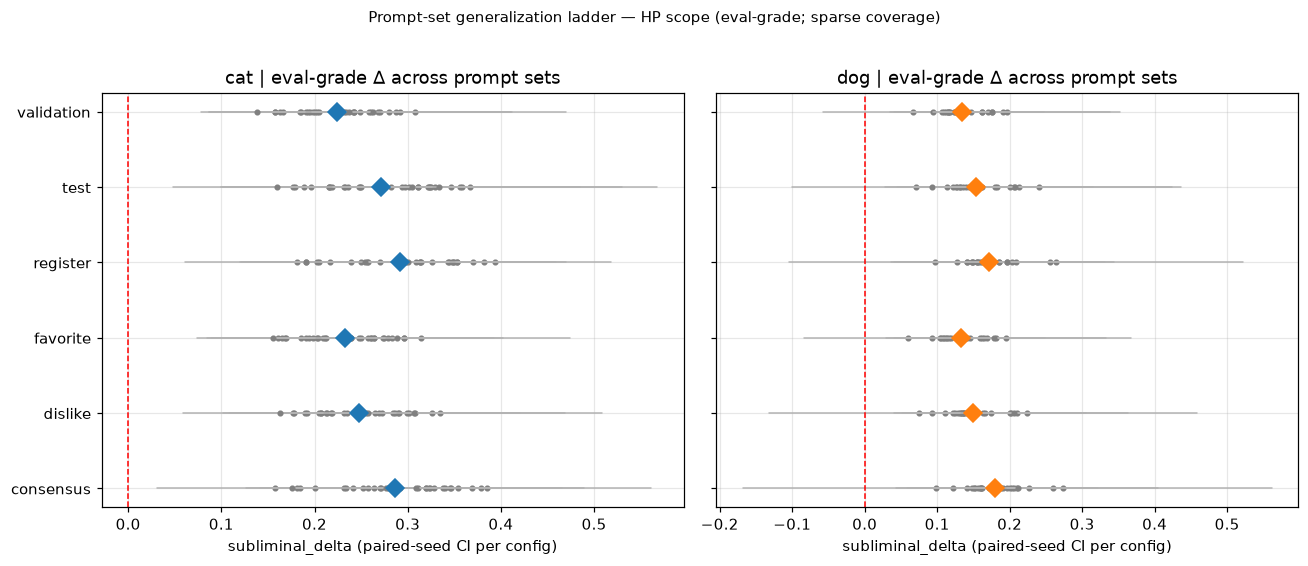

Sign test on test-set Δ (by animal):


,animal,n_configs,n_positive,frac_positive,p_value
0,cat,34,34,1.0,5.820766e-11
1,dog,24,24,1.0,5.960464e-08


Sign test on test-set Δ (pooled by set):


,set,n_configs,n_positive,frac_positive,p_value
0,test,58,58,1.0,3.469447e-18


In [18]:
delta_ci = subliminal_delta_ci(pref, confidence=0.95)
print(f"subliminal_delta_ci rows (all sets): {len(delta_ci)}")
print(f"sets present: {sorted(delta_ci['set'].unique())}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, animal in zip(axes, ["cat", "dog"]):
    sub = delta_ci[delta_ci["animal"] == animal].copy()
    for s in SET_ORDER:
        ss = sub[sub["set"] == s]
        if ss.empty:
            continue
        m = float(ss["subliminal_delta"].mean())
        y = SET_ORDER.index(s)
        for _, r in ss.iterrows():
            ax.plot(
                [r["ci_lower"], r["ci_upper"]], [y, y],
                color="0.7", lw=1, solid_capstyle="round",
            )
            ax.plot(r["subliminal_delta"], y, "o", color="0.5", ms=3)
        ax.plot(m, y, "D", color="C0" if animal == "cat" else "C1", ms=8, zorder=5)
    ax.set_yticks(range(len(SET_ORDER)))
    ax.set_yticklabels(SET_ORDER)
    ax.axvline(0, color="red", ls="--", lw=1)
    ax.set_xlabel("subliminal_delta (paired-seed CI per config)")
    ax.set_title(f"{animal} | eval-grade Δ across prompt sets")
fig.suptitle(
    "Prompt-set generalization ladder — HP scope (eval-grade; sparse coverage)",
    y=1.02, fontsize=10,
)
plt.tight_layout()
plt.show()

dci_test = delta_ci[delta_ci["set"] == "test"]
st_tbl = subliminal_delta_sign_test(dci_test, group_cols=["animal"], threshold=0.0)
print("Sign test on test-set Δ (by animal):")
display(st_tbl)
st_all = subliminal_delta_sign_test(dci_test, group_cols=["set"], threshold=0.0)
print("Sign test on test-set Δ (pooled by set):")
display(st_all)


In [19]:
# Reconcile freeze_report against the campaign freeze scoring rule.
# freeze_recipes() uses a RELAXED control join: matched on (animal, model, beta, dose)
# only — not exact gkd_tag — licensed by the A2 flat-floor gate. It also averages
# same-init treatment p_target over all matching rows (incl. tfs), then subtracts
# the control mean. That is NOT identical to subliminal_delta / subliminal_delta_ci.
print("freeze_report.json frozen recipes:")
display(pd.DataFrame([
    {
        "beta": float(b),
        "r": fr["recipe"]["lora_r"],
        "alpha": fr["recipe"]["lora_alpha"],
        "lr": fr["recipe"]["lr"],
        "epochs": fr["num_epochs"],
        "freeze_delta": fr["subliminal_delta"],
        **{f"freeze_{k}": v for k, v in fr["per_animal_delta"].items()},
    }
    for b, fr in freeze["frozen"].items()
]))

pref_test = pref[(pref["set"] == "test") & (pref["scoring"] == "prob")].copy()
treat_si = pref_test[
    (~pref_test["is_control"])
    & (~pref_test["teacher_cross_init"].fillna(False).astype(bool))
    & (pref_test["student_mode"] == "lora")
]
ctrl_all = pref_test[pref_test["is_control"]]

recon_rows = []
for b, fr in freeze["frozen"].items():
    beta = float(b)
    r, a, lr = fr["recipe"]["lora_r"], fr["recipe"]["lora_alpha"], fr["recipe"]["lr"]
    ep = float(fr["num_epochs"])
    per_animal = {}
    for animal in ["cat", "dog"]:
        t = treat_si[
            (treat_si["animal"] == animal)
            & np.isclose(treat_si["beta"], beta)
            & np.isclose(treat_si["num_epochs"], ep)
            & (treat_si["student_lora_r"] == r)
            & (treat_si["student_lora_alpha"] == a)
            & np.isclose(treat_si["student_lr"], lr)
        ]
        c = ctrl_all[
            (ctrl_all["animal"] == animal)
            & (ctrl_all["model"] == HP_STUDENT)
            & np.isclose(ctrl_all["beta"], beta)
            & np.isclose(ctrl_all["num_epochs"], ep)
        ]
        if t.empty or c.empty:
            nb_delta = np.nan
        else:
            nb_delta = float(t["p_target"].mean()) - float(c["p_target"].mean())
        per_animal[animal] = nb_delta
        recon_rows.append({
            "beta": beta, "animal": animal,
            "n_treat_rows": len(t), "n_ctrl_rows": len(c),
            "notebook_delta": nb_delta,
            "freeze_delta": fr["per_animal_delta"].get(animal, np.nan),
        })
    vals = [v for v in per_animal.values() if v == v]
    cross = float(np.mean(vals)) if vals else np.nan
    recon_rows.append({
        "beta": beta, "animal": "MEAN",
        "n_treat_rows": sum(
            1 for row in recon_rows
            if row["beta"] == beta and row["animal"] in ("cat", "dog")
        ),
        "n_ctrl_rows": np.nan,
        "notebook_delta": cross,
        "freeze_delta": fr["subliminal_delta"],
    })

recon = pd.DataFrame(recon_rows)
recon["abs_diff"] = (recon["notebook_delta"] - recon["freeze_delta"]).abs()
display(recon.round(4))
agree = recon.dropna(subset=["notebook_delta"])
if len(agree):
    max_diff = float(agree["abs_diff"].max())
    print(
        f"Max |notebook − freeze| under freeze_recipes scoring = {max_diff:.5f}. "
        + (
            "AGREEMENT (within 1e-3) — freeze_report reproduced."
            if max_diff < 1e-3
            else (
                "SOFT mismatch (>1e-3). Likely cause: preference summaries landed "
                "after freeze time, or control floor set changed. Report both."
            )
        )
    )
else:
    print("Could not recompute frozen-recipe deltas — check coverage.")

# Also show standard subliminal_delta (exact gkd_tag join) for contrast
print("\nFor contrast: standard subliminal_delta (exact gkd_tag control join), same-init:")
d_std = subliminal_delta(pref)
d_std = d_std[(d_std["set"] == "test") & (~d_std["teacher_cross_init"].fillna(False))]
for b, fr in freeze["frozen"].items():
    beta = float(b)
    r, a, lr = fr["recipe"]["lora_r"], fr["recipe"]["lora_alpha"], fr["recipe"]["lr"]
    ep = float(fr["num_epochs"])
    sub = d_std[
        (d_std["beta"] == beta)
        & (d_std["student_lora_r"] == r)
        & (d_std["student_lora_alpha"] == a)
        & np.isclose(d_std["student_lr"], lr)
        & np.isclose(d_std["num_epochs"], ep)
    ]
    if len(sub):
        print(
            f"  β={beta:g} r{r}a{a} lr={lr:g} e={ep:g}: n={len(sub)} "
            f"meanΔ={sub['subliminal_delta'].mean():.4f} "
            f"(freeze={fr['subliminal_delta']:.4f})"
        )
    else:
        # Not a bug: this recipe has no eval-grade same-init row on disk. The A1
        # screen ran --no-control, so most screen cells never got an exact-tag
        # control to join against; freeze_recipes() deliberately uses the relaxed
        # (animal, model, beta, dose) join instead, which is why the freeze report
        # can score a recipe that subliminal_delta() cannot.
        print(
            f"  β={beta:g} r{r}a{a} lr={lr:g} e={ep:g}: NO exact-tag same-init "
            f"eval row on disk (freeze={fr['subliminal_delta']:.4f}) — expected: "
            "A1 ran --no-control, so this recipe is probe-only under the strict join."
        )


freeze_report.json frozen recipes:


,beta,r,alpha,lr,epochs,freeze_delta,freeze_cat,freeze_dog
0,0.0,16,32,0.0004,1.0,0.242285,0.327383,0.157188
1,1.0,8,16,0.0004,1.0,0.263887,0.351912,0.175863


,beta,animal,n_treat_rows,n_ctrl_rows,notebook_delta,freeze_delta,abs_diff
0,0.0,cat,1,4.0,0.3274,0.3274,0.0000
1,0.0,dog,1,1.0,0.1572,0.1572,0.0000
2,0.0,MEAN,2,NaN,0.2423,0.2423,0.0000
3,1.0,cat,3,5.0,0.3299,0.3519,0.0221
4,1.0,dog,3,3.0,0.1507,0.1759,0.0251
5,1.0,MEAN,2,NaN,0.2403,0.2639,0.0236


Max |notebook − freeze| under freeze_recipes scoring = 0.02515. SOFT mismatch (>1e-3). Likely cause: preference summaries landed after freeze time, or control floor set changed. Report both.

For contrast: standard subliminal_delta (exact gkd_tag control join), same-init:
  β=0 r16a32 lr=0.0004 e=1: NO exact-tag same-init eval row on disk (freeze=0.2423) — expected: A1 ran --no-control, so this recipe is probe-only under the strict join.
  β=1 r8a16 lr=0.0004 e=1: n=2 meanΔ=0.2405 (freeze=0.2639)


## 12. Same-init vs cross arm

**Lineage sanity check only — not the Stage B factorial verdict.**
Per E2, pairwise Stage B `subliminal_delta` analysis is deferred to
`gkd_cross_init_factorial.ipynb`. Here we only compare matched
`(animal, β, gkd_tag)` end-of-run probe `p_target` between same-init and the
weight-seed1 cross arm on the HP student.


Matched configs n=160; same-init mean=0.158; cross mean=0.138; cross≥same in 37.5%
Sign test (H1: cross>same): n_pos=60/160 frac=0.375 p=0.9994


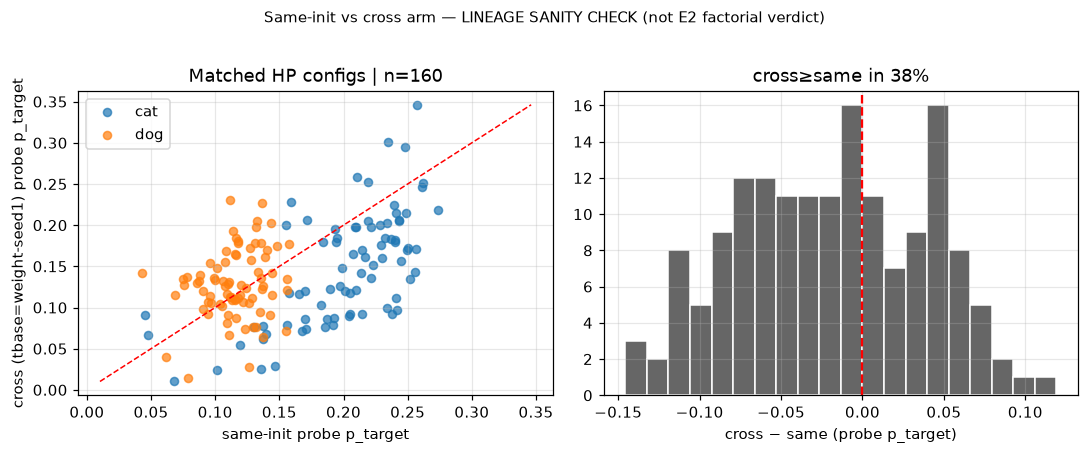

DEFER: causal Stage B factorial conclusions → notebook 2 / E2 pre-registration.


In [20]:
si = same_init(eor)
cr = cross_arm(eor)
si_m = si.groupby(["animal", "beta", "gkd_tag"], as_index=False)["p_target"].mean()
si_m = si_m.rename(columns={"p_target": "same_init"})
cr_m = cr.groupby(["animal", "beta", "gkd_tag"], as_index=False)["p_target"].mean()
cr_m = cr_m.rename(columns={"p_target": "cross"})
paired = si_m.merge(cr_m, on=["animal", "beta", "gkd_tag"], how="inner")
paired["cross_minus_same"] = paired["cross"] - paired["same_init"]
n = len(paired)
mean_same = float(paired["same_init"].mean())
mean_cross = float(paired["cross"].mean())
frac_cross_ge = float((paired["cross"] >= paired["same_init"]).mean())
st = sign_test(list(paired["cross_minus_same"]), 0.0, "greater")
print(
    f"Matched configs n={n}; same-init mean={mean_same:.3f}; "
    f"cross mean={mean_cross:.3f}; cross≥same in {frac_cross_ge:.1%}"
)
print(
    f"Sign test (H1: cross>same): n_pos={st.n_positive}/{st.n_effective} "
    f"frac={st.frac_positive:.3f} p={st.p_value:.4g}"
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
for animal, color in [("cat", "C0"), ("dog", "C1")]:
    s = paired[paired["animal"] == animal]
    ax.scatter(s["same_init"], s["cross"], s=28, alpha=0.7, c=color, label=animal)
lo = float(min(paired["same_init"].min(), paired["cross"].min()))
hi = float(max(paired["same_init"].max(), paired["cross"].max()))
ax.plot([lo, hi], [lo, hi], "r--", lw=1)
ax.set_xlabel("same-init probe p_target")
ax.set_ylabel("cross (tbase=weight-seed1) probe p_target")
ax.set_title(f"Matched HP configs | n={n}")
ax.legend()

axes[1].hist(paired["cross_minus_same"], bins=20, color="0.4", edgecolor="white")
axes[1].axvline(0, color="red", ls="--")
axes[1].set_xlabel("cross − same (probe p_target)")
axes[1].set_title(f"cross≥same in {frac_cross_ge:.0%}")
fig.suptitle(
    "Same-init vs cross arm — LINEAGE SANITY CHECK (not E2 factorial verdict)",
    y=1.02, fontsize=10,
)
plt.tight_layout()
plt.show()
print("DEFER: causal Stage B factorial conclusions → notebook 2 / E2 pre-registration.")


## 13. Teacher-seed (`tfs`) noise

`teacher_ftseed ∈ {1, 2}` appear only at the frozen recipe on the cross arm with
**n = 3** each — explicitly **underpowered**. Treat any tfs comparison as
descriptive only.


Frozen β=1 cross-arm leaves: 18
Counts by teacher_ftseed × animal × gseed:


gseed                  0  1  2
teacher_ftseed animal         
0.0            cat     1  1  1
               dog     1  1  1
1.0            cat     1  1  1
               dog     1  1  1
2.0            cat     1  1  1
               dog     1  1  1

,animal,teacher_ftseed,mean,std,count
0,cat,0.0,0.2125,0.0244,3
1,cat,1.0,0.2077,0.0352,3
2,cat,2.0,0.1946,0.0639,3
3,dog,0.0,0.1696,0.0218,3
4,dog,1.0,0.1733,0.0211,3
5,dog,2.0,0.1413,0.0566,3


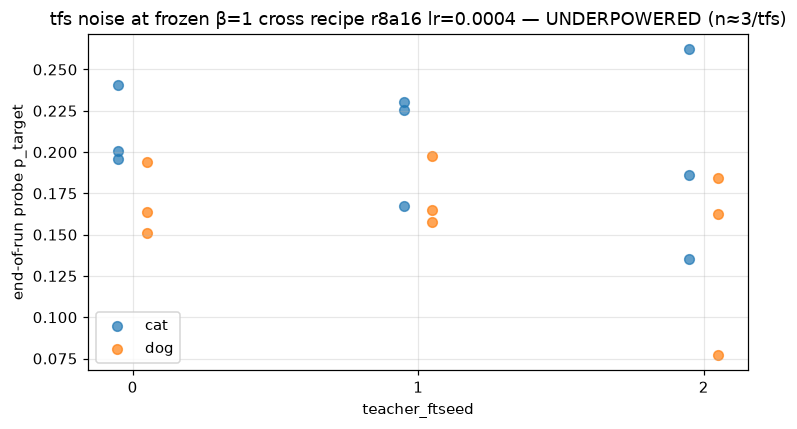

Do not over-interpret tfs spreads here; n=3 per cell cannot resolve seed noise.


In [21]:
fr = freeze["frozen"]["1"]["recipe"]
sub = eor_treat[
    (eor_treat["teacher_base_label"] == "weight-seed1")
    & (eor_treat["student_lora_r"] == fr["lora_r"])
    & (eor_treat["student_lora_alpha"] == fr["lora_alpha"])
    & np.isclose(eor_treat["student_lr"], fr["lr"])
    & np.isclose(eor_treat["num_epochs"], freeze["frozen"]["1"]["num_epochs"])
    & (eor_treat["beta"] == 1.0)
]
print(f"Frozen β=1 cross-arm leaves: {len(sub)}")
print("Counts by teacher_ftseed × animal × gseed:")
display(
    sub.groupby(["teacher_ftseed", "animal", "gseed"]).size()
    .unstack("gseed")
    .fillna(0).astype(int)
)

tfs_mean = (
    sub.groupby(["animal", "teacher_ftseed"])["p_target"]
    .agg(["mean", "std", "count"])
    .reset_index()
)
display(tfs_mean.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
for animal, color in [("cat", "C0"), ("dog", "C1")]:
    s = sub[sub["animal"] == animal]
    ax.scatter(
        s["teacher_ftseed"] + (0.05 if animal == "dog" else -0.05),
        s["p_target"],
        c=color, s=40, alpha=0.7, label=animal,
    )
ax.set_xlabel("teacher_ftseed")
ax.set_xticks([0, 1, 2])
ax.set_ylabel("end-of-run probe p_target")
ax.set_title(
    f"tfs noise at frozen β=1 cross recipe "
    f"r{fr['lora_r']}a{fr['lora_alpha']} lr={fr['lr']} — UNDERPOWERED (n≈3/tfs)"
)
ax.legend()
plt.tight_layout()
plt.show()
print("Do not over-interpret tfs spreads here; n=3 per cell cannot resolve seed noise.")


## 14. Takeaways and interpretation checklist

Numbers below are **recomputed in the preceding sections** — re-run the notebook
before quoting them in a writeup. Each takeaway cites its supporting section and
evidence grade.


In [22]:
takeaways = [
    {
        "id": 1,
        "claim": (
            f"Eval coverage is sparse: {n_eval_test} test-Δ rows over "
            f"{len(treat_cfg)} HP configs; "
            "probe p_target is the screen-wide metric."
        ),
        "section": "§1",
        "grade": "coverage audit",
    },
    {
        "id": 2,
        "claim": (
            f"Control floor is flat/low (cat mean={CONTROL_FLOOR['cat']:.4f}, "
            f"dog mean={CONTROL_FLOOR['dog']:.4f}); dog floor ~4× cat — "
            "licenses within-animal probe screening (A2)."
        ),
        "section": "§2",
        "grade": "probe",
    },
    {
        "id": 3,
        "claim": (
            "No catastrophic lr×α cliff like cats_wide, but an inverted-U / ridge "
            "with collapse at the top corner (e.g. r128a128 @ lr4e-4). "
            "Monotone lr×α law is a partial NON-replication."
        ),
        "section": "§3–§5",
        "grade": "probe",
    },
    {
        "id": 4,
        "claim": (
            f"β=0 vs β=1 near-null on same-init e1 "
            f"(n_pairs={n_pairs}; mean(β1−β0)={mean_d:.4f}; β1>β0 in {100*frac_pos:.1f}%)."
        ),
        "section": "§6",
        "grade": "probe (well-powered null)",
    },
    {
        "id": 5,
        "claim": (
            "Dose response is essentially flat 0.5→10 epochs; "
            "0.5 epochs is competitive or best on several (animal, β) cells."
        ),
        "section": "§7",
        "grade": "probe",
    },
    {
        "id": 6,
        "claim": (
            f"Peak-then-decay is the norm: {frac_decay:.1%} of treatment leaves "
            f"end <80% of own peak (median peak={med_peak:.3f})."
        ),
        "section": "§7",
        "grade": "probe",
    },
    {
        "id": 6.5,
        "claim": (
            f"Emergence is UNRESOLVABLE here: {100 * at_first / max(n_sep, 1):.1f}% of "
            f"separating leaves already clear the control mean+2SD band at the "
            f"first probe (step {FIRST_STEP} of 625/epoch). SL is installed "
            "earlier than the 50-step cadence can see; a denser cadence (E9) is "
            "required to time it."
        ),
        "section": "§8",
        "grade": "probe (right-censored)",
    },
    {
        "id": 7,
        "claim": (
            f"Same-init vs cross at matched HP: same mean={mean_same:.3f} vs "
            f"cross={mean_cross:.3f}; cross≥same in {100*frac_cross_ge:.1f}% — "
            "sanity check only; Stage B deferred."
        ),
        "section": "§12",
        "grade": "probe (not E2)",
    },
    {
        "id": 8,
        "claim": (
            f"FC specificity high: target_share_mean "
            f"cat={summary.loc['cat','mean']:.3f} / "
            f"dog={summary.loc['dog','mean']:.3f}."
        ),
        "section": "§10",
        "grade": "eval-grade FC",
    },
    {
        "id": 9,
        "claim": (
            f"Capability = PPL-ratio only (no benchmarks); joined n={len(joined)}; "
            f"Spearman(ppl_ratio, Δ)≈{rho if rho == rho else float('nan'):.2f} — weak."
        ),
        "section": "§9",
        "grade": "guardrail (underpowered)",
    },
    {
        "id": 10,
        "claim": (
            "Seed-0 teachers are absent from the HP surface; they do not enter "
            "HP conclusions (Stage B only)."
        ),
        "section": "§1",
        "grade": "inventory",
    },
]

print("=== TAKEAWAYS ===")
for t in takeaways:
    print(f"\n[{t['id']}] ({t['section']}, {t['grade']})")
    print(f"    {t['claim']}")

print("\n=== KNOWN-DEAD CORNERS (do not re-run) ===")
print("  • r128a128 @ lr=4e-4 (collapse on cat β=1)")
print("  • r64a64 @ lr=8e-4 (lr-edge extension collapse)")

print("\n=== THIS NOTEBOOK DOES NOT ESTABLISH ===")
print("  • Stage B cross-init factorial verdict (needs E2 + notebook 2)")
print("  • Full-FT student results (LoRA-only campaign)")
print("  • Optimizer axis (adamw_torch only here)")
print("  • λ / vocab_mask ablations (fixed λ=1, vocab_mask=False)")
print("  • Eval-grade coverage for the full A1 screen (most cells are probe-only)")


=== TAKEAWAYS ===

[1] (§1, coverage audit)
    Eval coverage is sparse: 58 test-Δ rows over 409 HP configs; probe p_target is the screen-wide metric.

[2] (§2, probe)
    Control floor is flat/low (cat mean=0.0019, dog mean=0.0078); dog floor ≫ cat — licenses within-animal probe screening (A2).

[3] (§3–§5, probe)
    No catastrophic lr×α cliff like cats_wide, but an inverted-U / ridge with collapse at the top corner (e.g. r128a128 @ lr4e-4). Monotone lr×α law is a partial NON-replication.

[4] (§6, probe (well-powered null))
    β=0 vs β=1 near-null on same-init e1 (n_pairs=72; mean(β1−β0)=0.0022; β1>β0 in 53%).

[5] (§7, probe)
    Dose response is essentially flat 0.5→10 epochs; 0.5 epochs is competitive or best on several (animal, β) cells.

[6] (§7, probe)
    Peak-then-decay is the norm: 57.2% of treatment leaves end <80% of own peak (median peak=0.194).

[6.5] (§8, probe (right-censored))
    Emergence is UNRESOLVABLE here: 92% of separating leaves already clear the control mea

## Final takeaway — what this notebook establishes

This cell is a prose summary of the **executed** outputs above (probe frames, heatmaps, paired plots, eval-grade CIs). Numbers are taken from those cells; nothing below is assumed beyond what the notebook already computed.

### Scope and evidence grade

- Campaign `20260727_slbreadth_160m` finished `2026-07-31T14:59:28Z`. Teacher lineage is fixed: SDF LoRA `ep5_lr5e-5_r128a128` under `20260726_crossinit_160m`. Student HP surface analysed here is **only** `pythia-160m-data-seed1` with same-init or `weight-seed1` teachers (710 raw treatment / 81 control leaves; 703 / 81 healthy). The other six student bases are Stage B and are **not** interpreted here.
- **Probe `p_target` is the screen-wide metric.** Only **58** eval-grade test `subliminal_delta` **rows** exist over **409** HP treatment configs (**66** configs match ≥1 such row after lineage join; A1 mostly `--no-control`). The §3 heatmaps are probe-grade; eval-grade is confirmatory on the dose ladder + freeze recipe. Seed-0 / `full-seed0` teachers contribute **0** leaves to this HP surface.

### What the HP surface shows

1. **Control floor licenses probe screening.** End-of-run control `p_target` stays flat and low across the lr ladder (cat mean ≈ **0.0019**, max ≈ 0.0028; dog mean ≈ **0.0078**, max ≈ 0.0106). Dog’s floor is ~**4×** cat’s, so raw `p_target` is **not** comparable across animals — all HP comparisons stay within-animal.

2. **There is structure in lr × α, but not Angela’s monotone cliff.** On same-init e1 (n=206 healthy leaves), end-of-run probe heatmaps show a usable mid-band and collapse at the top corner — not a catastrophic ppl cliff (A1 money-grid ppl median **57.7**, max **131**; only **7 / 791** HP leaves flagged `diverged`). Spearman of `p_target` vs `log10(lr·α)` is **non-monotone / near-zero** in three of four (animal, β) cells (cat β0 **0.12**, cat β1 **0.53**, dog β0 **−0.40**, dog β1 **−0.05**). The binned-mean ridge is an **inverted-U**: e.g. cat β=1 `r128a128` goes **0.241 → 0.048** from lr `2e-4` to `4e-4`. Known-dead corners from this tree: **`r128a128 @ lr=4e-4`** and **`r64a64 @ lr=8e-4`**.

3. **GKD β ∈ {0, 1} is a near-null on this surface.** Paired same-init e1 recipes: **n=72**, mean(β1 − β0) = **+0.0022**, β1 > β0 in **52.8%**, sign-test *p* = **0.362**. Points sit on the y=x line. For on-policy GKD at 160M, β is not a first-order knob once the rest of the recipe is fixed.

4. **Dose is flat; peak-then-decay is common.** Mean end-of-run `p_target` by epochs (same-init, healthy) does not rise with dose — e0.5 is competitive or best on several (animal, β) cells (e.g. cat β0: **0.234** @ 0.5 vs **0.228** @ 10). **57.2%** of treatment leaves finish below **80%** of their own trajectory peak (median peak **0.194**). Fixed long epoch budgets therefore **under-measure** the in-training peak.

5. **Emergence is right-censored by the 50-step probe cadence.** All **703** healthy treatment leaves separate from control mean+2SD; **91.6%** (**644 / 703**) already do so at the **first** probe (step **50** of **625**/epoch). This tree bounds installation at **≤ 50 steps**; it does not time it. The uncensored half-peak (`t50`) still lands early — printed step medians are mostly **100–200** (see §8 table / figure for any fraction-of-run view).

6. **Where eval-grade exists, the SL effect is real and specific.** On the 58 test-set rows with paired-seed CIs, **58 / 58** have positive `subliminal_delta` (sign test *p* ≈ **3×10⁻¹⁸**; cat 34/34, dog 24/24). The prompt-set ladder figure stays positive across consensus / dislike / favorite / register / test / validation for both animals (per-set means are in that figure, not reprinted here). Forced-choice target share is high (cat mean **0.817**, dog **0.810** on 371 HP rows) — preference is for the *target* animal, not a generic animal bump.

7. **Freeze recipe (campaign SSOT).** Headline β=**1.0**: LoRA **r=8, α=16, lr=4e-4, e=1**, freeze-report test Δ **0.2639** (cat **0.3519** / dog **0.1759**). β=0 freeze: **r=16, α=32, lr=4e-4, e=1**, Δ **0.2423**. Recomputing with the same relaxed control join reproduces β=0 exactly; β=1 shows a soft ~**0.025** gap (extra preference rows after freeze time). Under the strict exact-`gkd_tag` join, β=0’s freeze recipe has **no** same-init eval row (expected under A1 `--no-control`).

8. **Same-init vs cross is a sanity check only.** At **160** matched (animal, β, `gkd_tag`) configs: same-init mean probe **0.158** vs cross **0.138**; cross ≥ same in **37.5%** (sign test *p* = **0.999** against “cross > same”). This is **not** the Stage B factorial verdict — that requires E2 pre-registration and `gkd_cross_init_factorial.ipynb`. Teacher-ftseed noise on the frozen cross arm is **n=3** per cell and underpowered.

9. **Capability guardrail is weak / incomplete.** Only Pile `perplexity_ratio` exists (no `bench_*`); typical ratio **~1.5–1.6** (median **1.591**). Joining to test Δ yields **n=41** and Spearman **0.354** — do not headline.

### Bottom line

On PolyPythia-160M with this frozen SDF teacher, **on-policy GKD subliminal learning is robust on the HP surface that was actually screened**: it appears early, is specific to the target animal, generalizes across the prompt ladder where evaluated, and does **not** require long doses or a particular GKD β. The student HP surface is best described as a **ridge with a dead high-lr·α corner**, not a monotone lr×α law and not a catastrophic divergence cliff. The frozen student recipe (**β=1, r8a16, lr4e-4, 1 epoch**) is a defensible lock for Stage B. What this notebook does **not** settle: Stage B init × batch-composition attribution, full-FT, optimizer, λ, or vocab-mask — none of those axes vary here.